In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

In [4]:
df_onecoin = pd.read_csv('reddit_sentiment_data_Onecoin_2024.csv')
df_ftx = pd.read_csv('reddit_sentiment_data_FTX_2024.csv')
df_celsius = pd.read_csv('reddit_sentiment_data_Celsius_2024.csv')
df_centra = pd.read_csv('reddit_sentiment_data_Centra_2024.csv')

In [5]:
df_onecoin["source"] = "OneCoin"
df_ftx["source"] = "FTX"
df_centra["source"] = "Centra"
df_celsius["source"] = "Celsius"

In [6]:
# import pandas as pd

# # Load all sources
# df_reddit      = pd.read_csv('reddit_sentiment_data_FTX.csv')
# df_news        = pd.read_csv('newsapi_crypto_scam_data.csv')
# df_gdelt       = pd.read_csv('gdelt_crypto_scam_data.csv')
# df_bitcointalk = pd.read_csv('bitcointalk_scam_data.csv')

# # Standardize columns so all sources have same structure
# df_reddit['data_source']      = 'Reddit'
# df_news['data_source']        = 'NewsAPI'
# df_gdelt['data_source']       = 'GDELT'
# df_bitcointalk['data_source'] = 'Bitcointalk'

# # Keep only shared columns
# SHARED_COLS = ['text', 'author', 'timestamp_utc', 'data_source']

# df_all = pd.concat([
#     df_reddit[SHARED_COLS],
#     df_news[SHARED_COLS],
#     df_gdelt[SHARED_COLS],
#     df_bitcointalk[SHARED_COLS]
# ], ignore_index=True)

# df_all['timestamp_utc'] = pd.to_datetime(df_all['timestamp_utc'], errors='coerce')
# df_all = df_all.dropna(subset=['text', 'timestamp_utc'])

# print(df_all['data_source'].value_counts())
# print(f"Total records: {len(df_all)}")

In [7]:
#  standardize time column
def standardize_time(df):
    df['timestamp_utc'] = pd.to_datetime(df['timestamp_utc'], errors='coerce')
    df["year_month"] = df['timestamp_utc'].dt.to_period('M')
    return df

df_onecoin = standardize_time(df_onecoin)
df_ftx = standardize_time(df_ftx)
df_centra = standardize_time(df_centra)
df_celsius = standardize_time(df_celsius)

In [ ]:
def clean_text(text):
    text = text.lower()
    # text = re.sub(r"http\S+", "", text)   # remove URLs
    text = re.sub(r"[^a-z\s]", "", text)  # remove punctuation
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# df_onecoin['cleaned_text'] = df_onecoin['text'].apply(clean_text)
# df_ftx['cleaned_text'] = df_ftx['text'].apply(clean_text)
# df_centra['cleaned_text'] = df_centra['text'].apply(clean_text)
# df_celsius['cleaned_text'] = df_celsius['text'].apply(clean_text)


In [9]:
df_all = pd.concat([df_onecoin, df_ftx, df_centra, df_celsius], ignore_index=True)  

In [10]:
# Step 1: count URLs on the original raw text first
df_all['url_count'] = df_all['text'].str.count(r'https?://\S+')

# Step 2: THEN apply cleaning as before
df_all['cleaned_text'] = df_all['text'].fillna('').astype(str).apply(clean_text)

In [11]:
df_all.count()

id               195556
subreddit        195556
type             195556
author           195556
timestamp_utc    195556
text             195550
parent_id        192462
source           195556
year_month       195556
url_count        195550
cleaned_text     195556
dtype: int64

In [12]:
df_all.head()

,id,subreddit,type,author,timestamp_utc,text,parent_id,source,year_month,url_count,cleaned_text
0,7r6chx,cryptocurrency,post,PM_Poutine,2018-01-18 02:04:30,Here is a list of crypto ponzi schemes and peo...,NaN,OneCoin,2018-01,2.0,here is a list of crypto ponzi schemes and peo...
1,dsukfjh,cryptocurrency,comment,[deleted],2018-01-18 02:21:43,"Great, I got 4 hours ago into this whole topic...",t3_7r6chx,OneCoin,2018-01,0.0,great i got hours ago into this whole topic an...
2,dsukd60,cryptocurrency,comment,BamboozleVictim,2018-01-18 02:20:27,"Theres one that just finished their ICO, BitAI...",t3_7r6chx,OneCoin,2018-01,0.0,theres one that just finished their ico bitai ...
3,dsumrvh,cryptocurrency,comment,[deleted],2018-01-18 03:07:24,Whilst not on his youtube as far as i know Moe...,t3_7r6chx,OneCoin,2018-01,0.0,whilst not on his youtube as far as i know moe...
4,dsukssd,cryptocurrency,comment,krypt0maniac,2018-01-18 02:29:00,This is a great resource. Thanks for taking th...,t3_7r6chx,OneCoin,2018-01,0.0,this is a great resource thanks for taking the...


In [13]:
# text-based features
df_all['text_length'] = df_all['cleaned_text'].apply(len)
df_all['word_count'] = df_all['cleaned_text'].apply(lambda x: len(x.split()))
df_all['url_count'] = df_all['cleaned_text'].str.count('http')

heuristic scam score

In [14]:
# scam keyword flags
scam_keywords = ['scam', 'double', 'fake', 'wallet drained', 'phishing', 'risk-free', 'urgent', 'impersonation', 'no loss','limited time', 'secret',  'hack', 'malware', 'suspicious', 'unverified',  'investment opportunity', 'fraud', 'deceptive']
def contains_scam_keywords(text):
    return sum(1 for k in scam_keywords if k in text)

df_all['contains_scam_keywords'] = df_all['cleaned_text'].apply(contains_scam_keywords)
df_all.head()

,id,subreddit,type,author,timestamp_utc,text,parent_id,source,year_month,url_count,cleaned_text,text_length,word_count,contains_scam_keywords
0,7r6chx,cryptocurrency,post,PM_Poutine,2018-01-18 02:04:30,Here is a list of crypto ponzi schemes and peo...,NaN,OneCoin,2018-01,2,here is a list of crypto ponzi schemes and peo...,2789,373,1
1,dsukfjh,cryptocurrency,comment,[deleted],2018-01-18 02:21:43,"Great, I got 4 hours ago into this whole topic...",t3_7r6chx,OneCoin,2018-01,0,great i got hours ago into this whole topic an...,133,28,0
2,dsukd60,cryptocurrency,comment,BamboozleVictim,2018-01-18 02:20:27,"Theres one that just finished their ICO, BitAI...",t3_7r6chx,OneCoin,2018-01,0,theres one that just finished their ico bitai ...,196,31,0
3,dsumrvh,cryptocurrency,comment,[deleted],2018-01-18 03:07:24,Whilst not on his youtube as far as i know Moe...,t3_7r6chx,OneCoin,2018-01,0,whilst not on his youtube as far as i know moe...,161,30,1
4,dsukssd,cryptocurrency,comment,krypt0maniac,2018-01-18 02:29:00,This is a great resource. Thanks for taking th...,t3_7r6chx,OneCoin,2018-01,0,this is a great resource thanks for taking the...,160,29,0


In [15]:
# Metadata features
df_all['is_comment'] = df_all['type'].apply(lambda x: 1 if x == 'comment' else 0)
df_all['is_deleted_author'] = df_all['author'].apply(lambda x: 1 if x == '[deleted]' else 0)
df_all['hour'] = df_all['timestamp_utc'].dt.hour
df_all['day_of_week'] = df_all['timestamp_utc'].dt.dayofweek
df_all['date'] = df_all['timestamp_utc'].dt.date
df_all['year_month'] = df_all['timestamp_utc'].dt.to_period('M')
df_all['year'] = df_all['timestamp_utc'].dt.year
df_24_25 = df_all[df_all['year'].isin([2023, 2024, 2025, 2026])]
df_24_25.head()

,id,subreddit,type,author,timestamp_utc,text,parent_id,source,year_month,url_count,cleaned_text,text_length,word_count,contains_scam_keywords,is_comment,is_deleted_author,hour,day_of_week,date,year
711,167j14k,cryptocurrency,post,pseudoHappyHippy,2023-09-01 21:03:31,"TIL that Ruja Ignatova, after founding a huge ...",NaN,OneCoin,2023-09,3,til that ruja ignatova after founding a huge f...,2579,431,3,0,0,21,4,2023-09-01,2023
712,jyq0uoz,cryptocurrency,comment,diarpiiiii,2023-09-01 21:13:41,Highly recommend the BBC podcast about this st...,t3_167j14k,OneCoin,2023-09,1,highly recommend the bbc podcast about this st...,127,12,0,1,0,21,4,2023-09-01,2023
713,jyr94mc,cryptocurrency,comment,djsimmy365,2023-09-02 02:36:59,"Holy cow, this whole story is insane and so di...",t3_167j14k,OneCoin,2023-09,0,holy cow this whole story is insane and so dis...,215,39,0,1,0,2,5,2023-09-02,2023
714,jyq19sn,cryptocurrency,comment,[deleted],2023-09-01 21:16:21,[deleted],t3_167j14k,OneCoin,2023-09,0,deleted,7,1,0,1,1,21,4,2023-09-01,2023
715,jyq2zet,cryptocurrency,comment,Dubznation300,2023-09-01 21:27:24,Who the hell gave her 4 billion,t3_167j14k,OneCoin,2023-09,0,who the hell gave her billion,29,6,0,1,0,21,4,2023-09-01,2023


Scam Growth over time -> Number of scam messages per year per scam type

In [16]:
print(df_all['year'].value_counts().sort_index())

year
2017      1752
2018      1524
2019       427
2020       916
2021     25057
2022    103969
2023     44746
2024     10220
2025      6945
Name: count, dtype: int64


In [17]:
# scam_count_year = df_all.groupby(['year', 'source']).size().reset_index(name='count')
# scam_count_year
count_24_25 = (
    df_24_25
    .groupby(['year_month', 'source'])
    .size()
    .reset_index(name='count')
)

count_24_25['year_month'] = count_24_25['year_month'].astype(str)

count_24_25.head()



,year_month,source,count
0,2023-01,Celsius,2311
1,2023-01,FTX,6897
2,2023-01,OneCoin,583
3,2023-02,Celsius,1057
4,2023-02,Centra,8


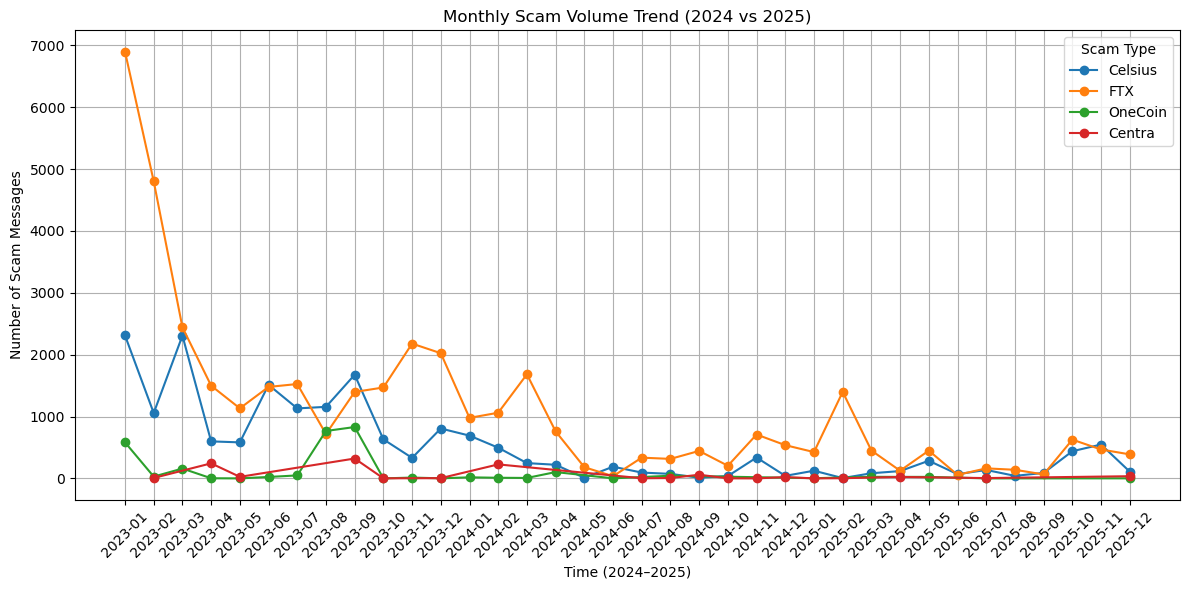

In [18]:
# plt.figure(figsize=(10,6))

# for scam in scam_count_year['source'].unique():
#     temp = scam_count_year[scam_count_year['source'] == scam]
#     plt.plot(temp['year'], temp['count'], marker='o', label=scam)

# plt.xlabel("Year")
# plt.ylabel("Number of Scam Messages")
# plt.title("Year-wise Growth of Different Scam Types")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()
plt.figure(figsize=(12,6))

for scam in count_24_25['source'].unique():
    temp = count_24_25[count_24_25['source'] == scam]
    plt.plot(
        temp['year_month'],
        temp['count'],
        marker='o',
        label=scam
    )

plt.xlabel("Time (2024–2025)")
plt.ylabel("Number of Scam Messages")
plt.title("Monthly Scam Volume Trend (2024 vs 2025)")
plt.xticks(rotation=45)
plt.legend(title="Scam Type")
plt.grid(True)
plt.tight_layout()

In [19]:

def heuristic_score(text):
    text = str(text).lower()
    return sum(word in text for word in scam_keywords)

df_all["heuristic_score"] = df_all["text"].apply(heuristic_score)
df_all["heuristic_label"] = (df_all["heuristic_score"] >= 2).astype(int)
df_all.head()

,id,subreddit,type,author,timestamp_utc,text,parent_id,source,year_month,url_count,...,word_count,contains_scam_keywords,is_comment,is_deleted_author,hour,day_of_week,date,year,heuristic_score,heuristic_label
0,7r6chx,cryptocurrency,post,PM_Poutine,2018-01-18 02:04:30,Here is a list of crypto ponzi schemes and peo...,NaN,OneCoin,2018-01,2,...,373,1,0,0,2,3,2018-01-18,2018,1,0
1,dsukfjh,cryptocurrency,comment,[deleted],2018-01-18 02:21:43,"Great, I got 4 hours ago into this whole topic...",t3_7r6chx,OneCoin,2018-01,0,...,28,0,1,1,2,3,2018-01-18,2018,0,0
2,dsukd60,cryptocurrency,comment,BamboozleVictim,2018-01-18 02:20:27,"Theres one that just finished their ICO, BitAI...",t3_7r6chx,OneCoin,2018-01,0,...,31,0,1,0,2,3,2018-01-18,2018,0,0
3,dsumrvh,cryptocurrency,comment,[deleted],2018-01-18 03:07:24,Whilst not on his youtube as far as i know Moe...,t3_7r6chx,OneCoin,2018-01,0,...,30,1,1,1,3,3,2018-01-18,2018,1,0
4,dsukssd,cryptocurrency,comment,krypt0maniac,2018-01-18 02:29:00,This is a great resource. Thanks for taking th...,t3_7r6chx,OneCoin,2018-01,0,...,29,0,1,0,2,3,2018-01-18,2018,0,0


In [20]:


import numpy as np
from sklearn.preprocessing import MinMaxScaler

# create needed columns first
df_all['long_text_flag'] = (df_all['text_length'] > 500).astype(int)
df_all['scam_keyword_count'] = df_all['contains_scam_keywords']  # align names

features = ['scam_keyword_count', 'url_count', 'is_deleted_author', 'long_text_flag']
scaler = MinMaxScaler()
df_all[features] = scaler.fit_transform(df_all[features])

df_all['scam_score'] = (
    0.4 * df_all['scam_keyword_count'] +
    0.2 * df_all['url_count'] +
    0.2 * df_all['is_deleted_author'] +
    0.2 * df_all['long_text_flag']
)

# Post must have a score > 0 AND meet a specific quantile
threshold = df_all[df_all['scam_score'] > 0]['scam_score'].median() # Quantile of ONLY non-zero scores
df_all['scam_likelihood'] = (df_all['scam_score'] > 0) & (df_all['scam_score'] >= threshold)
print("Scam Score Distribution:\n", df_all['scam_score'].value_counts().head())
print("\nCalculated Threshold:", df_all['scam_score'].quantile(0.75))
print("Class Counts:\n", df_all['scam_likelihood'].value_counts())


Scam Score Distribution:
 scam_score
0.000000    151066
0.200000     27879
0.057143      6698
0.000800      3238
0.257143      1860
Name: count, dtype: int64

Calculated Threshold: 0.0
Class Counts:
 scam_likelihood
False    162579
True      32977
Name: count, dtype: int64


In [21]:
# sentiment analysis
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer 
analyzer = SentimentIntensityAnalyzer()
df_all['sentiment'] = df_all['cleaned_text'].apply(lambda x: analyzer.polarity_scores(x)['compound'])

# -1 -> very negative
# 0 -> neutral
# 1 -> very positive

In [22]:
# scam vs non-scam classifier 
#  features for model
FEATURES = [
    'text_length',
    'word_count',
    'url_count',
    'contains_scam_keywords',
    'is_comment',
    'sentiment'
]
target = df_all[FEATURES]
labels = df_all['scam_likelihood']
df_all.head()

,id,subreddit,type,author,timestamp_utc,text,parent_id,source,year_month,url_count,...,day_of_week,date,year,heuristic_score,heuristic_label,long_text_flag,scam_keyword_count,scam_score,scam_likelihood,sentiment
0,7r6chx,cryptocurrency,post,PM_Poutine,2018-01-18 02:04:30,Here is a list of crypto ponzi schemes and peo...,NaN,OneCoin,2018-01,0.008,...,3,2018-01-18,2018,1,0,1.0,0.142857,0.258743,True,0.9816
1,dsukfjh,cryptocurrency,comment,[deleted],2018-01-18 02:21:43,"Great, I got 4 hours ago into this whole topic...",t3_7r6chx,OneCoin,2018-01,0.000,...,3,2018-01-18,2018,0,0,0.0,0.000000,0.200000,True,0.5702
2,dsukd60,cryptocurrency,comment,BamboozleVictim,2018-01-18 02:20:27,"Theres one that just finished their ICO, BitAI...",t3_7r6chx,OneCoin,2018-01,0.000,...,3,2018-01-18,2018,0,0,0.0,0.000000,0.000000,False,0.4404
3,dsumrvh,cryptocurrency,comment,[deleted],2018-01-18 03:07:24,Whilst not on his youtube as far as i know Moe...,t3_7r6chx,OneCoin,2018-01,0.000,...,3,2018-01-18,2018,1,0,0.0,0.142857,0.257143,True,0.0516
4,dsukssd,cryptocurrency,comment,krypt0maniac,2018-01-18 02:29:00,This is a great resource. Thanks for taking th...,t3_7r6chx,OneCoin,2018-01,0.000,...,3,2018-01-18,2018,0,0,0.0,0.000000,0.000000,False,0.9008


In [23]:
# Train model
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

X_train, X_test, Y_train, Y_test = train_test_split(target, labels, test_size=0.3, random_state=42)
classify = RandomForestClassifier(n_estimators=200, random_state=42) 
classify.fit(X_train, Y_train)
Y_pred = classify.predict(X_test)
print(classification_report(Y_test, Y_pred))

              precision    recall  f1-score   support

       False       0.91      0.98      0.95     48849
        True       0.86      0.53      0.66      9818

    accuracy                           0.91     58667
   macro avg       0.89      0.76      0.80     58667
weighted avg       0.90      0.91      0.90     58667



In [24]:
# use heuristic score as pseudo labels
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train, Y_train)
lr_probs = lr.predict_proba(X_test)[:, 1]
pd.Series(lr.coef_[0], index=target.columns)

text_length               0.007098
word_count               -0.019475
url_count                -0.012834
contains_scam_keywords   -0.153377
is_comment                0.366386
sentiment                -0.126091
dtype: float64

In [25]:
rf_probs = classify.predict_proba(X_test)[:, 1]
pd.Series(classify.feature_importances_, index=X_train.columns).sort_values(ascending=False)

text_length               0.507439
sentiment                 0.251015
word_count                0.230569
url_count                 0.006846
contains_scam_keywords    0.002583
is_comment                0.001549
dtype: float64

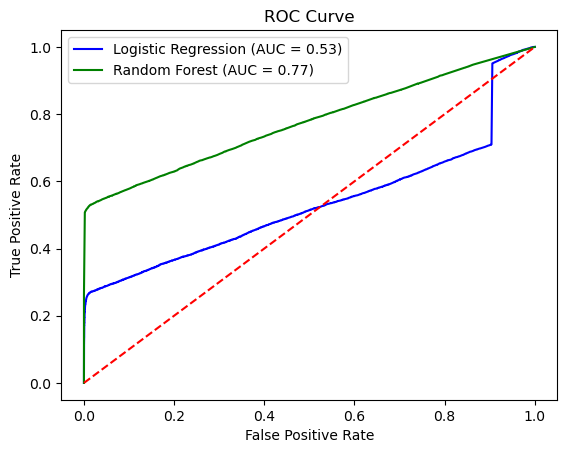

In [26]:
# Roc-auc analysis
from sklearn.metrics import roc_curve, auc
Y_prob = lr.predict_proba(X_test)[:, 1]
Y_prob_1 = classify.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(Y_test, Y_prob)
roc_auc = auc(fpr, tpr)
import matplotlib.pyplot as plt
fpr1, tpr1, _ = roc_curve(Y_test, Y_prob_1)
roc_auc1 = auc(fpr1, tpr1)
plt.figure()
plt.plot(fpr, tpr, color='blue', label='Logistic Regression (AUC = {:.2f})'.format(roc_auc))
plt.plot(fpr1, tpr1, color='green', label='Random Forest (AUC = {:.2f})'.format(roc_auc1))
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()  

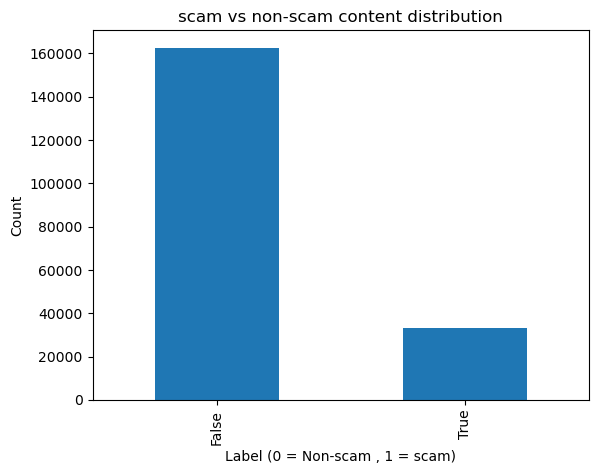

In [27]:
# Scam vs Non-scam distribution

import seaborn as sns
df_all['scam_likelihood'].value_counts().plot(kind='bar')
plt.title("scam vs non-scam content distribution")
plt.xlabel("Label (0 = Non-scam , 1 = scam)")
plt.ylabel("Count")
plt.show()

<Axes: xlabel='hour'>

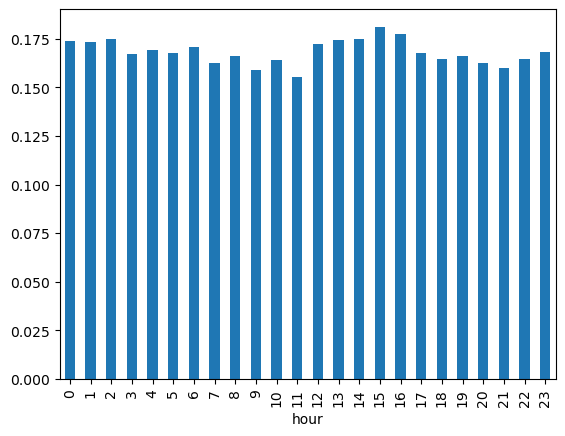

In [28]:
# time-based analysis
df_all['hour'] = df_all['timestamp_utc'].dt.hour
df_all.groupby('hour')['scam_likelihood'].mean().plot(kind = 'bar')

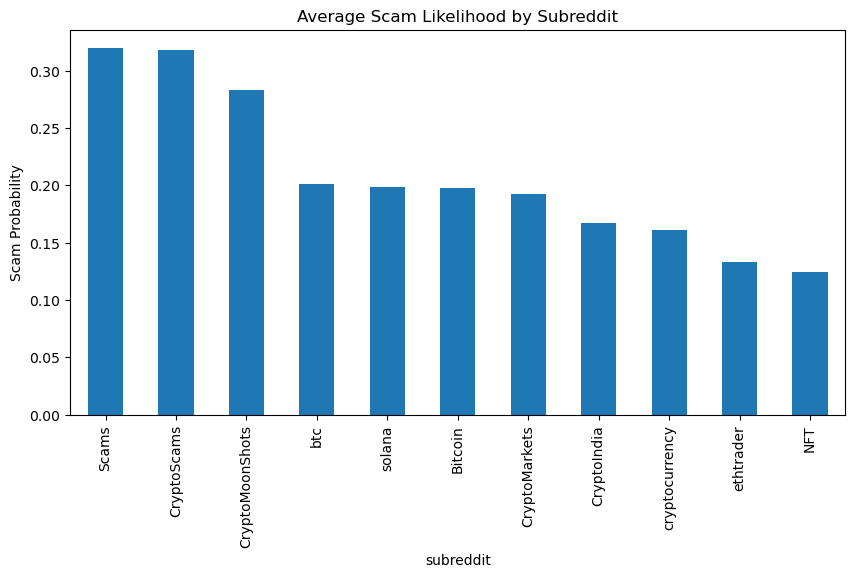

In [29]:
# Subreddit-wise Scam Density
subreddit_scam = df_all.groupby('subreddit')['scam_likelihood'].mean().sort_values(ascending=False)

subreddit_scam.plot(kind='bar', figsize=(10,5))
plt.title("Average Scam Likelihood by Subreddit")
plt.ylabel("Scam Probability")
plt.show()

bert scam classification

In [ ]:
import os

if os.path.exists("all_scores.parquet"):
    saved = pd.read_parquet("all_scores.parquet")
    df_all["bert_score"]    = saved["bert_score"]
    df_all["roberta_score"] = saved["roberta_score"]
    print("✓ Scores loaded from disk — skipping inference")
else:
    # Run the full inference only the first time
    df_all["bert_score"] = bert_score(df_all["text"].tolist())
    df_all["roberta_score"] = roberta_score(df_all["text"].tolist())
    df_all[["bert_score", "roberta_score"]].to_parquet("all_scores.parquet", index=True)
    print("✓ Inference done and saved")

In [30]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

# # Load FinBERT
# tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
# model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert")
# model.eval()  # ⬅ Important: inference mode

# def bert_score(text_list):
#     """
#     Computes FinBERT scam probability scores for a list of texts.
#     Returns a list of probabilities for class index 1.
#     """
#     scores = []

#     with torch.no_grad():  # ⬅ No gradients needed for inference
#         for sentence in text_list:
#             inputs = tokenizer(
#                 sentence,
#                 return_tensors="pt",
#                 padding=True,
#                 truncation=True,
#                 max_length=128
#             )

#             outputs = model(**inputs)
#             logits = outputs.logits
#             probs = torch.softmax(logits, dim=1)

#             scam_prob = probs[:, 1].item()  # Probability of class 1
#             scores.append(scam_prob)

#     return scores


In [31]:
from transformers import pipeline

In [29]:
from transformers import pipeline

# Drop-in replacement — same logic, much smaller model
zs_classifier = pipeline(
    "zero-shot-classification",
    model="cross-encoder/nli-MiniLM2-L6-H768",
    device=-1   # CPU
)

CANDIDATE_LABELS = ["cryptocurrency scam", "legitimate discussion"]

def bert_score(text_list, batch_size=64):   # can use bigger batch now
    scores = []
    for i in range(0, len(text_list), batch_size):
        batch = text_list[i : i + batch_size]
        batch = [str(t)[:512] for t in batch]
        results = zs_classifier(batch, CANDIDATE_LABELS)
        for res in results:
            idx = res["labels"].index("cryptocurrency scam")
            scores.append(res["scores"][idx])
        
        # Progress tracker so you know it's running
        if (i // batch_size) % 10 == 0:
            print(f"Processed {i}/{len(text_list)} posts...")
    
    return scores

df_all["bert_score"] = bert_score(df_all["text"].tolist())

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/328M [00:00<?, ?B/s]

c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025EA4DA90A0> was reported to be 64(when accessing len(dataloader)), but 65 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025EA4DA90A0> was reported to be 64(when accessing len(dataloader)), but 66 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025EA4DA90A0> was reported to be 64(when accessing len(dataloader)), but 67 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torc

Processed 0/195556 posts...


c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025EA4DA9070> was reported to be 64(when accessing len(dataloader)), but 65 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025EA4DA9070> was reported to be 64(when accessing len(dataloader)), but 66 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025EA4DA9070> was reported to be 64(when accessing len(dataloader)), but 67 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torc

Processed 640/195556 posts...


... (95 outputs left out)

Processed 185600/195556 posts...
Processed 186240/195556 posts...
Processed 186880/195556 posts...
Processed 187520/195556 posts...


c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025EA7587610> was reported to be 64(when accessing len(dataloader)), but 65 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025EA7587610> was reported to be 64(when accessing len(dataloader)), but 66 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025EA7587610> was reported to be 64(when accessing len(dataloader)), but 67 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torc

Processed 188160/195556 posts...
Processed 188800/195556 posts...
Processed 189440/195556 posts...
Processed 190080/195556 posts...
Processed 190720/195556 posts...
Processed 191360/195556 posts...
Processed 192000/195556 posts...
Processed 192640/195556 posts...
Processed 193280/195556 posts...
Processed 193920/195556 posts...
Processed 194560/195556 posts...
Processed 195200/195556 posts...


c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025E4D6988B0> was reported to be 36(when accessing len(dataloader)), but 37 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025E4D6988B0> was reported to be 36(when accessing len(dataloader)), but 38 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000025E4D6988B0> was reported to be 36(when accessing len(dataloader)), but 39 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torc

In [32]:
# Save only the score column — that's all that took 3-4 hours to compute
df_all[["bert_score"]].to_parquet("bert_scores.parquet", index=True)
print("✓ bert_score saved")


KeyError: "None of [Index(['bert_score'], dtype='object')] are in the [columns]"

0 → positive
1 → negative
2 → neutral

In [33]:
import pandas as pd

# Load scores back and merge onto df_all by index
saved_scores = pd.read_parquet("bert_scores.parquet")
df_all["bert_score"] = saved_scores["bert_score"]

print("✓ bert_score loaded — no inference needed")

✓ bert_score loaded — no inference needed


In [30]:
# # df_test = df_all.iloc[X_test.index]
# # best_probs = bert_score(df_test['text'].tolist())
# df_test = df_all.iloc[X_test.index] 
# df_test["bert_score"] = bert_score(df_test["text"].tolist())

# df_all["bert_score"] = bert_score(df_all["text"].tolist())



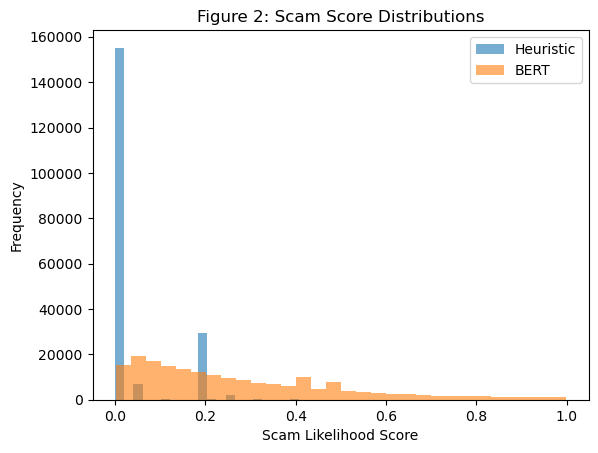

In [34]:
plt.figure()
plt.hist(df_all['scam_score'], bins=30, alpha=0.6, label="Heuristic")
plt.hist(df_all['bert_score'], bins=30, alpha=0.6, label="BERT")
# plt.hist(df_all['roberta_score'], bins=30, alpha=0.6, label="RoBERTa")

plt.xlabel("Scam Likelihood Score")
plt.ylabel("Frequency")
plt.legend()
plt.title("Figure 2: Scam Score Distributions")
plt.show()


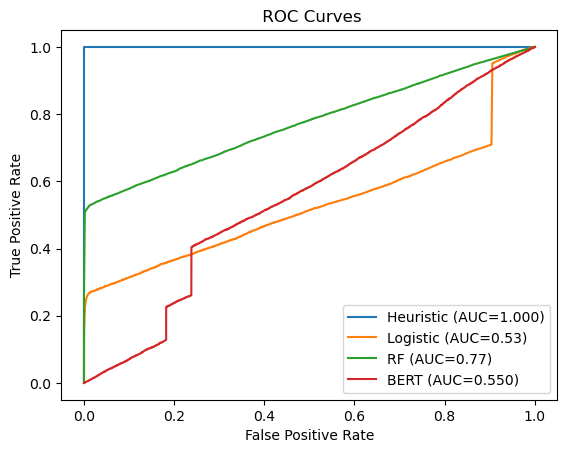

In [35]:
plt.figure()

# ensure df_test exists (rows corresponding to X_test)
df_test = df_all.loc[X_test.index]

# Heuristic
fpr_h, tpr_h, _ = roc_curve(Y_test, df_test['scam_score'])
plt.plot(fpr_h, tpr_h, label=f"Heuristic (AUC={auc(fpr_h,tpr_h):.3f})")

# Logistic
fpr_lr, tpr_lr, _ = roc_curve(Y_test, lr_probs)
plt.plot(fpr_lr, tpr_lr, label=f"Logistic (AUC={auc(fpr_lr,tpr_lr):.2f})")

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(Y_test, rf_probs)
plt.plot(fpr_rf, tpr_rf, label=f"RF (AUC={auc(fpr_rf,tpr_rf):.2f})")

# BERT
fpr_b, tpr_b, _ = roc_curve(Y_test, df_test['bert_score'])
plt.plot(fpr_b, tpr_b, label=f"BERT (AUC={auc(fpr_b,tpr_b):.3f})")


plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title(" ROC Curves")
plt.show()


C:\Users\User\AppData\Local\Temp\ipykernel_17904\2264200477.py:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  temporal_df = df_all.groupby(df_all['timestamp_utc'].dt.to_period("H"))['scam_score'].mean()


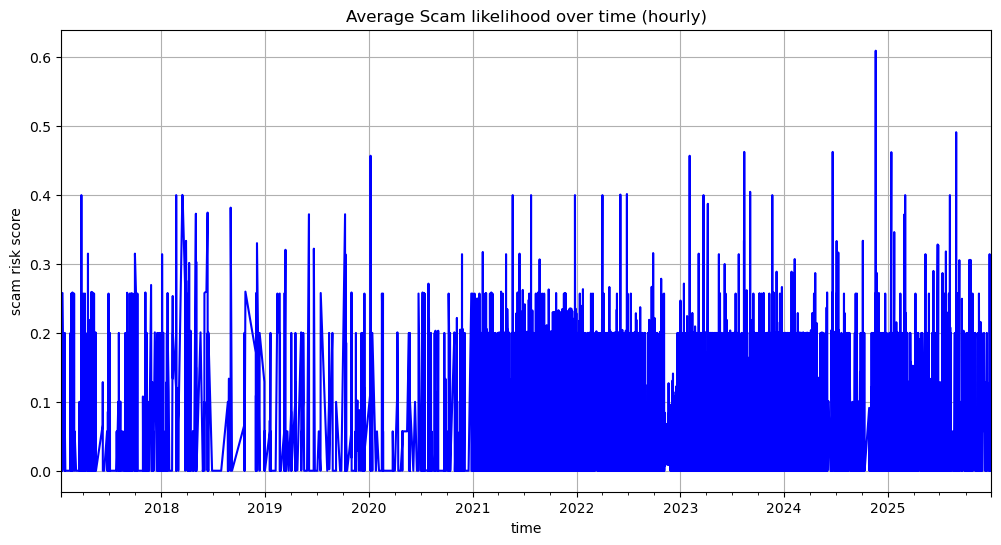

In [36]:
# Group by hour and calculate the mean scam score
temporal_df = df_all.groupby(df_all['timestamp_utc'].dt.to_period("H"))['scam_score'].mean()
plt.figure(figsize = (12,6))
temporal_df.plot(kind='line', color = 'blue')
plt.title('Average Scam likelihood over time (hourly)')
plt.ylabel('scam risk score')
plt.xlabel('time')
plt.grid(True)
plt.show()

In [37]:
from sklearn.ensemble import IsolationForest

# Use raw features to find outliers (potential 'novel' scams)
iso_forest = IsolationForest(contamination=0.05, random_state=42)
df_all['is_anomaly'] = iso_forest.fit_predict(df_all[FEATURES])

# Anomalies are marked as -1
novel_scams = df_all[df_all['is_anomaly'] == -1]
print(f"Detected {len(novel_scams)} anomalous posts that may be 'new' scam types.")

Detected 9778 anomalous posts that may be 'new' scam types.


In [38]:
# Regex patterns for common crypto addresses
eth_pattern = r'0x[a-fA-F0-0]{40}'
btc_pattern = r'[13][a-km-zA-HJ-NP-Z1-9]{25,34}'

def extract_wallets(text):
    wallets = re.findall(eth_pattern, text) + re.findall(btc_pattern, text)
    return list(set(wallets))

# Regex patterns for common crypto addresses
eth_pattern = r'0x[a-fA-F0-9]{40}'
btc_pattern = r'\b[13][a-km-zA-HJ-NP-Z1-9]{25,34}\b'

def extract_wallets(text):
    if not isinstance(text, str):
        return []
    wallets = re.findall(eth_pattern, text) + re.findall(btc_pattern, text)
    return list(set(wallets))

df_all['detected_wallets'] = df_all['text'].fillna('').astype(str).apply(extract_wallets)

unique_wallets = df_all[df_all['detected_wallets'].map(len) > 0]['detected_wallets'].explode().unique()
print(f"Found {len(unique_wallets)} unique crypto addresses for blacklisting.")


Found 549 unique crypto addresses for blacklisting.


SVM-linear/ RBF -> why add svm? strong baseline for high-dimensional text features, often outperforms logistic regression on text, good comaprision with the random forest.

In [39]:
# from sklearn.svm import SVC
# from sklearn.pipeline import Pipeline
# from sklearn.feature_extraction.text import TfidfVectorizer


# svm_pipeline = Pipeline([
#     ('tfidf', TfidfVectorizer(max_features=10000, ngram_range=(1,2), stop_words='english')),
#     ('svm', SVC(kernel='linear', probability=True, class_weight='balanced'))
# ])
# svm_pipeline.fit(df_all.loc[X_train.index, 'cleaned_text'], Y_train)
# svm_pred = svm_pipeline.predict(df_all.loc[X_test.index, 'cleaned_text'])
# svm_probs = svm_pipeline.predict_proba(df_all.loc[X_test.index, 'cleaned_text'])[:, 1]
# print(classification_report(Y_test, svm_pred))
# print("ROC-AUC", roc_auc_score(Y_test, svm_probs))

XGBoost (Extreme gradient boosting) -> why add XGboost? very strong tree-based boosting model, handles non-linear feature interactions, excellent for tabular + engineered features.


In [40]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score
xgb_model = XGBClassifier(n_estimators=300, max_depth=6, eval_metric='logloss', random_state=42, learning_rate=0.05, subsample=0.8,colsample_bytree=0.8)
xgb_model.fit(X_train, Y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
print(classification_report(Y_test, xgb_pred))
print("ROC-AUC", roc_auc_score(Y_test, xgb_probs))

              precision    recall  f1-score   support

       False       0.91      1.00      0.95     48849
        True       0.97      0.50      0.66      9818

    accuracy                           0.91     58667
   macro avg       0.94      0.75      0.81     58667
weighted avg       0.92      0.91      0.90     58667

ROC-AUC 0.769628258272389


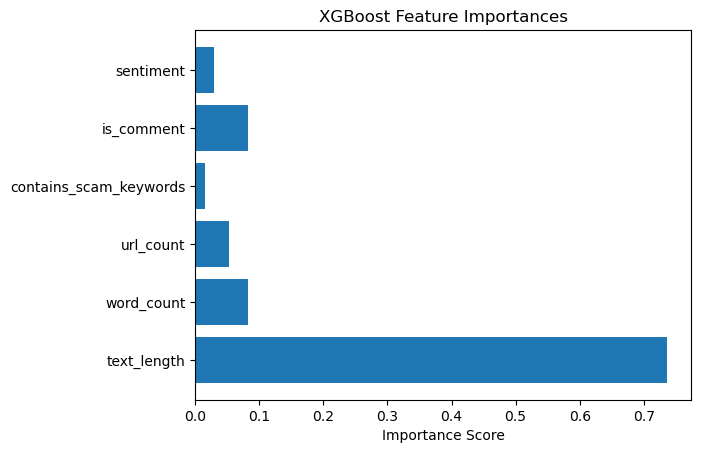

In [41]:
# feature importance
plt.figure()
plt.barh(X_train.columns, xgb_model.feature_importances_)
plt.title("XGBoost Feature Importances")
plt.xlabel("Importance Score")
plt.show()

RoBERTa(pre-trained transformer - better than bert) -> stronger language undersatnding than BERT, better at detecting subtle scam langauge, great for showing deep NLP improvement. BEST USE -> fine tuned binary classification on scam/non-scam text.

In [42]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "distilroberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
).to("cpu")
for param in model.base_model.parameters():
    param.requires_grad = False


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at distilroberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [43]:
from datasets import Dataset

# Convert Period columns to string to avoid Arrow type error
for col in df_all.columns:
    if isinstance(df_all[col].dtype, pd.PeriodDtype):
        df_all[col] = df_all[col].astype(str)

# Ensure `text` has no missing values and is always string
df_all['text'] = df_all['text'].fillna('').astype(str)

# Convert pandas DataFrame → HuggingFace Dataset
dataset = Dataset.from_pandas(df_all)
dataset = dataset.train_test_split(test_size=0.3, seed=42)

def tokenize_function(examples):
    texts = [str(t) for t in examples["text"]]
    return tokenizer(
        texts,
        truncation=True,
        padding="max_length",
        max_length=128
    )

tokenized_dataset = dataset.map(tokenize_function, batched=True)
tokenized_dataset = tokenized_dataset.remove_columns(["text"])
tokenized_dataset = tokenized_dataset.map(
    lambda examples: {"labels": examples["scam_likelihood"]},
    batched=True
)

train_small = tokenized_dataset["train"].shuffle(seed=42).select(range(min(3000, len(tokenized_dataset["train"]))))
test_small = tokenized_dataset["test"].shuffle(seed=42).select(range(min(1000, len(tokenized_dataset["test"]))))


Map:   0%|          | 0/136889 [00:00<?, ? examples/s]

Map:   0%|          | 0/58667 [00:00<?, ? examples/s]

Map:   0%|          | 0/136889 [00:00<?, ? examples/s]

Map:   0%|          | 0/58667 [00:00<?, ? examples/s]

In [ ]:
import sys
!{sys.executable} -m pip install --upgrade transformers accelerate


  Using cached transformers-4.57.6-py3-none-any.whl (12.0 MB)

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\User\\anaconda3\\Lib\\site-packages\\~okenizers\\tokenizers.cp39-win_amd64.pyd'
Consider using the `--user` option or check the permissions.




  Using cached accelerate-1.10.1-py3-none-any.whl (374 kB)
  Using cached tokenizers-0.22.2-cp39-abi3-win_amd64.whl (2.7 MB)
  Using cached safetensors-0.7.0-cp38-abi3-win_amd64.whl (341 kB)
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.12.1
    Uninstalling tokenizers-0.12.1:
      Successfully uninstalled tokenizers-0.12.1


In [44]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from datasets import Dataset, Value
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score
)
import numpy as np
import torch
import pandas as pd

# ═══════════════════════════════════════════════════════════
# STEP 1 — Reload model cleanly with correct config
# ═══════════════════════════════════════════════════════════
MODEL_NAME = "distilroberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels        = 2,
    problem_type      = "single_label_classification",  # ← forces CrossEntropyLoss
)

# ── Unfreeze ALL layers so the model trains properly ───────
for param in model.parameters():
    param.requires_grad = True

print(f"Model loaded: {MODEL_NAME}")
print(f"Problem type: {model.config.problem_type}")
print(f"Num labels  : {model.config.num_labels}")


# ═══════════════════════════════════════════════════════════
# STEP 2 — Rebuild datasets cleanly
# ═══════════════════════════════════════════════════════════

# Convert Period columns to string (Arrow doesn't support Period)
df_copy = df_all.copy()
for col in df_copy.columns:
    if hasattr(df_copy[col], 'dt') and hasattr(df_copy[col].dt, 'to_timestamp'):
        df_copy[col] = df_copy[col].astype(str)
    elif str(df_copy[col].dtype) == 'period[M]':
        df_copy[col] = df_copy[col].astype(str)

# Only keep the two columns we need
df_model = df_copy[['text', 'scam_likelihood']].copy()
df_model['labels'] = df_model['scam_likelihood'].astype(int)
df_model = df_model[['text', 'labels']].dropna()

# Build HuggingFace dataset
dataset = Dataset.from_pandas(df_model, preserve_index=False)

# Cast labels to int64 explicitly
dataset = dataset.cast_column("labels", Value("int64"))

# Train / test split
dataset = dataset.train_test_split(test_size=0.3, seed=42)

# Tokenize
def tokenize(examples):
    return tokenizer(
        examples["text"],
        truncation = True,
        padding    = "max_length",
        max_length = 128
    )

tokenized = dataset.map(tokenize, batched=True)

# Remove raw text column — keep only model inputs + labels
keep_cols = tokenizer.model_input_names + ["labels"]
tokenized = tokenized.remove_columns(
    [c for c in tokenized["train"].column_names if c not in keep_cols]
)

# Set torch format
tokenized["train"].set_format(type="torch", columns=keep_cols)
tokenized["test"].set_format(type="torch",  columns=keep_cols)

# Subsample for speed
train_small = tokenized["train"].shuffle(seed=42).select(range(3000))
test_small  = tokenized["test"].shuffle(seed=42).select(range(1000))

# ── Verify labels are correct ──────────────────────────────
sample = train_small[0]
print(f"\nLabel dtype : {sample['labels'].dtype}")   # must be torch.int64
print(f"Label value : {sample['labels'].item()}")    # must be 0 or 1
print(f"Input IDs   : {sample['input_ids'].shape}")  # must be torch.Size([128])


# ═══════════════════════════════════════════════════════════
# STEP 3 — Metrics
# ═══════════════════════════════════════════════════════════
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds          = np.argmax(logits, axis=1)
    acc            = accuracy_score(labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary", zero_division=0
    )
    probs = torch.softmax(torch.tensor(logits, dtype=torch.float32), dim=1)[:, 1].numpy()
    auc   = roc_auc_score(labels, probs)
    return {
        "accuracy":  round(acc,       4),
        "precision": round(precision, 4),
        "recall":    round(recall,    4),
        "f1":        round(f1,        4),
        "roc_auc":   round(auc,       4)
    }


# ═══════════════════════════════════════════════════════════
# STEP 4 — Train
# ═══════════════════════════════════════════════════════════
training_args = TrainingArguments(
    output_dir                  = "./fast_roberta",
    per_device_train_batch_size = 8,
    per_device_eval_batch_size  = 8,
    num_train_epochs            = 2,
    no_cuda                     = True,
    report_to                   = "none",
    evaluation_strategy         = "epoch",
    save_strategy               = "no",
    logging_steps               = 50,
    warmup_steps                = 100,
    weight_decay                = 0.01,
)

trainer = Trainer(
    model           = model,
    args            = training_args,
    train_dataset   = train_small,
    eval_dataset    = test_small,
    compute_metrics = compute_metrics
)

trainer.train()

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at distilroberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded: distilroberta-base
Problem type: single_label_classification
Num labels  : 2


Casting the dataset:   0%|          | 0/195556 [00:00<?, ? examples/s]

Map:   0%|          | 0/136889 [00:00<?, ? examples/s]

Map:   0%|          | 0/58667 [00:00<?, ? examples/s]


Label dtype : torch.int64
Label value : 0
Input IDs   : torch.Size([128])


... (4 outputs left out)

{'eval_loss': 0.3238338530063629, 'eval_accuracy': 0.899, 'eval_precision': 0.949, 'eval_recall': 0.4921, 'eval_f1': 0.6481, 'eval_roc_auc': 0.741, 'eval_runtime': 14.1495, 'eval_samples_per_second': 70.674, 'eval_steps_per_second': 8.834, 'epoch': 1.0}
{'loss': 0.342, 'grad_norm': 0.9313222169876099, 'learning_rate': 2.6923076923076923e-05, 'epoch': 1.07}
{'loss': 0.3529, 'grad_norm': 1.999065637588501, 'learning_rate': 2.307692307692308e-05, 'epoch': 1.2}
{'loss': 0.3036, 'grad_norm': 0.8980834484100342, 'learning_rate': 1.923076923076923e-05, 'epoch': 1.33}
{'loss': 0.2881, 'grad_norm': 1.7794593572616577, 'learning_rate': 1.5384615384615387e-05, 'epoch': 1.47}
{'loss': 0.4093, 'grad_norm': 1.3258039951324463, 'learning_rate': 1.153846153846154e-05, 'epoch': 1.6}
{'loss': 0.2626, 'grad_norm': 4.102630615234375, 'learning_rate': 7.692307692307694e-06, 'epoch': 1.73}
{'loss': 0.333, 'grad_norm': 1.8709020614624023, 'learning_rate': 3.846153846153847e-06, 'epoch': 1.87}
{'loss': 0.2854

  0%|          | 0/125 [00:00<?, ?it/s]

{'eval_loss': 0.34992578625679016, 'eval_accuracy': 0.897, 'eval_precision': 0.93, 'eval_recall': 0.4921, 'eval_f1': 0.6436, 'eval_roc_auc': 0.7482, 'eval_runtime': 14.2368, 'eval_samples_per_second': 70.241, 'eval_steps_per_second': 8.78, 'epoch': 2.0}
{'train_runtime': 560.6061, 'train_samples_per_second': 10.703, 'train_steps_per_second': 1.338, 'train_loss': 0.35758171463012695, 'epoch': 2.0}


TrainOutput(global_step=750, training_loss=0.35758171463012695, metrics={'train_runtime': 560.6061, 'train_samples_per_second': 10.703, 'train_steps_per_second': 1.338, 'total_flos': 198701097984000.0, 'train_loss': 0.35758171463012695, 'epoch': 2.0})

In [ ]:
# from datasets import Value
# import torch
# from transformers import TrainingArguments, Trainer
# from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
# import numpy as np

# # ── Fix 1: Cast labels to int64 IN the dataset schema ─────────────────────────
# # This forces set_format to produce torch.long instead of torch.float
# train_small = train_small.cast_column("labels", Value("int64"))
# test_small  = test_small.cast_column("labels", Value("int64"))

# # ── Fix 2: Keep only required columns ─────────────────────────────────────────
# keep_cols = tokenizer.model_input_names + ["labels"]

# train_small = train_small.remove_columns(
#     [c for c in train_small.column_names if c not in keep_cols]
# )
# test_small = test_small.remove_columns(
#     [c for c in test_small.column_names if c not in keep_cols]
# )

# # ── Fix 3: Set format AFTER cast_column ───────────────────────────────────────
# train_small.set_format(type="torch", columns=keep_cols)
# test_small.set_format(type="torch", columns=keep_cols)

# # ── Verify labels are now torch.long (should print torch.int64) ───────────────
# sample = train_small[0]
# print(f"Label dtype: {sample['labels'].dtype}")   # must show torch.int64
# print(f"Label value: {sample['labels']}")          # must show 0 or 1

# # ── Compute metrics ───────────────────────────────────────────────────────────
# def compute_metrics(eval_pred):
#     logits, labels = eval_pred
#     preds     = np.argmax(logits, axis=1)
#     acc       = accuracy_score(labels, preds)
#     precision, recall, f1, _ = precision_recall_fscore_support(
#         labels, preds, average="binary"
#     )
#     probs = torch.softmax(torch.tensor(logits), dim=1)[:, 1].numpy()
#     auc   = roc_auc_score(labels, probs)
#     return {
#         "accuracy":  acc,
#         "precision": precision,
#         "recall":    recall,
#         "f1":        f1,
#         "roc_auc":   auc
#     }

# # ── Training arguments ────────────────────────────────────────────────────────
# training_args = TrainingArguments(
#     output_dir                  = "./fast_roberta",
#     per_device_train_batch_size = 8,
#     per_device_eval_batch_size  = 8,
#     num_train_epochs            = 2,
#     no_cuda                     = True,    # ← back to no_cuda for older transformers
#     report_to                   = "none",
#     evaluation_strategy         = "epoch",
#     save_strategy               = "no",
#     logging_steps               = 50,
# )

# trainer = Trainer(
#     model           = model,
#     args            = training_args,
#     train_dataset   = train_small,
#     eval_dataset    = test_small,
#     compute_metrics = compute_metrics
# )

# trainer.train()



In [45]:
inference_dataset = Dataset.from_pandas(df_all)

inference_dataset = inference_dataset.map(
    tokenize_function,
    batched=True
)

inference_dataset = inference_dataset.remove_columns(
    [col for col in inference_dataset.column_names if col not in tokenizer.model_input_names]
)
predictions = trainer.predict(inference_dataset)
logits = predictions.predictions
probs = torch.softmax(torch.tensor(logits), dim=1)[:, 1].numpy()
df_all['roberta_score'] = probs

Map:   0%|          | 0/195556 [00:00<?, ? examples/s]

  0%|          | 0/24445 [00:00<?, ?it/s]

In [46]:
# Run this once after both score columns exist in df_all
df_all[["bert_score", "roberta_score"]].to_parquet("all_scores.parquet", index=True)
print("✓ Both scores saved")

✓ Both scores saved


In [47]:
saved = pd.read_parquet("all_scores.parquet")
df_all["bert_score"]    = saved["bert_score"]
df_all["roberta_score"] = saved["roberta_score"]

In [48]:
df_all.groupby("year_month")[["heuristic_score", "bert_score", "roberta_score"]].mean()


,heuristic_score,bert_score,roberta_score
year_month,,,
2017-01,0.140000,0.448757,0.106696
2017-02,0.290837,0.420525,0.167309
2017-03,0.086207,0.388661,0.114777
2017-04,0.155125,0.354113,0.190742
2017-05,0.186275,0.405790,0.198749
...,...,...,...
2025-08,0.137363,0.253554,0.151469
2025-09,0.149351,0.252784,0.160792
2025-10,0.044049,0.283133,0.156381


In [49]:
df_all[['heuristic_score', 'bert_score', 'roberta_score']].describe()


,heuristic_score,bert_score,roberta_score
count,195556.000000,195556.000000,195556.000000
mean,0.057641,0.277297,0.133709
std,0.266188,0.226414,0.265751
min,0.000000,0.000974,0.044485
25%,0.000000,0.094592,0.049153
50%,0.000000,0.215138,0.050133
75%,0.000000,0.405267,0.051380
max,7.000000,0.998455,0.997943


In [50]:
trend_df = df_all.groupby('year_month').agg(
    total_msgs=('text', 'count'),
    heuristic_avg=('heuristic_score', 'mean'),
    bert_avg=('bert_score', 'mean'),
    roberta_avg=('roberta_score', 'mean')
).reset_index()

trend_df['year_month'] = trend_df['year_month'].astype(str)

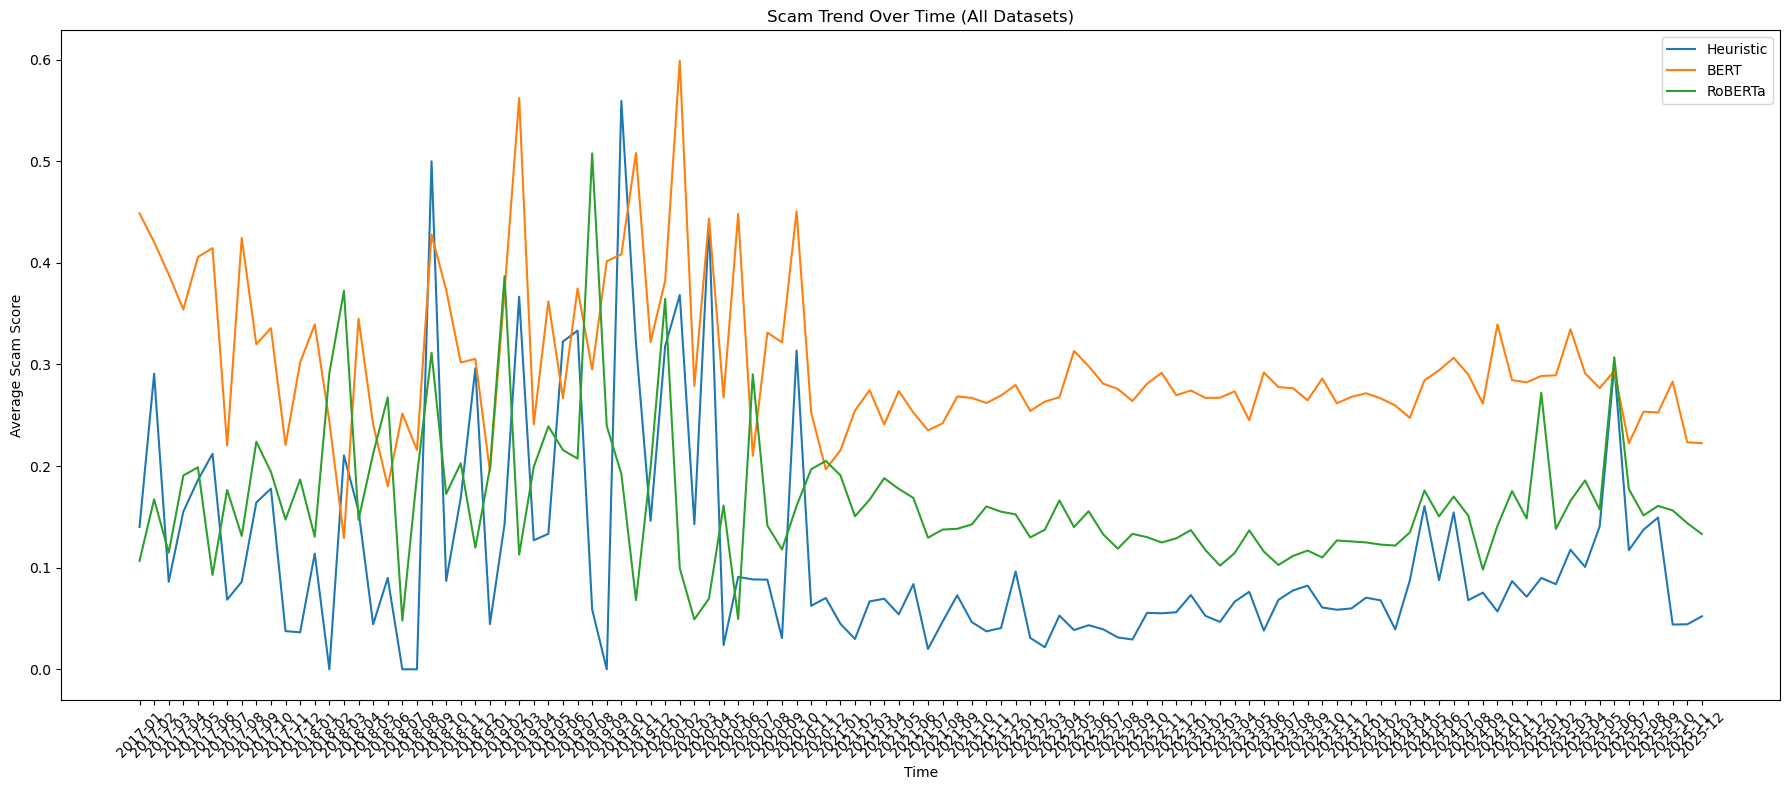

In [51]:
plt.figure(figsize=(18,8))
plt.plot(trend_df['year_month'], trend_df['heuristic_avg'], label='Heuristic')
plt.plot(trend_df['year_month'], trend_df['bert_avg'], label='BERT')
plt.plot(trend_df['year_month'], trend_df['roberta_avg'], label='RoBERTa')

plt.xticks(rotation=45)
plt.xlabel("Time")
plt.ylabel("Average Scam Score")
plt.title("Scam Trend Over Time (All Datasets)")
plt.legend()
plt.tight_layout()
plt.show()


In [52]:
# Define predictions using a threshold (e.g., 0.5)
heuristic_pred = (df_all['heuristic_score'] >= 2)  # as in your earlier heuristic_label
bert_pred = (df_all['bert_score'] > 0.5)
roberta_pred = (df_all['roberta_score'] > 0.5)

combined_analysis = pd.DataFrame({
    'Model': ['Heuristic', 'BERT', 'RoBERTa'],
    'Mean Scam Score': [
        df_all['heuristic_score'].mean(),
        df_all['bert_score'].mean(),
        df_all['roberta_score'].mean()
    ],
    'Score Std Dev': [
        df_all['heuristic_score'].std(),
        df_all['bert_score'].std(),
        df_all['roberta_score'].std()
    ],
    'Scam Rate (%)': [
        heuristic_pred.mean() * 100,
        bert_pred.mean() * 100,
        roberta_pred.mean() * 100
    ]
})

combined_analysis


,Model,Mean Scam Score,Score Std Dev,Scam Rate (%)
0,Heuristic,0.057641,0.266188,0.424942
1,BERT,0.277297,0.226414,15.488658
2,RoBERTa,0.133709,0.265751,8.929412


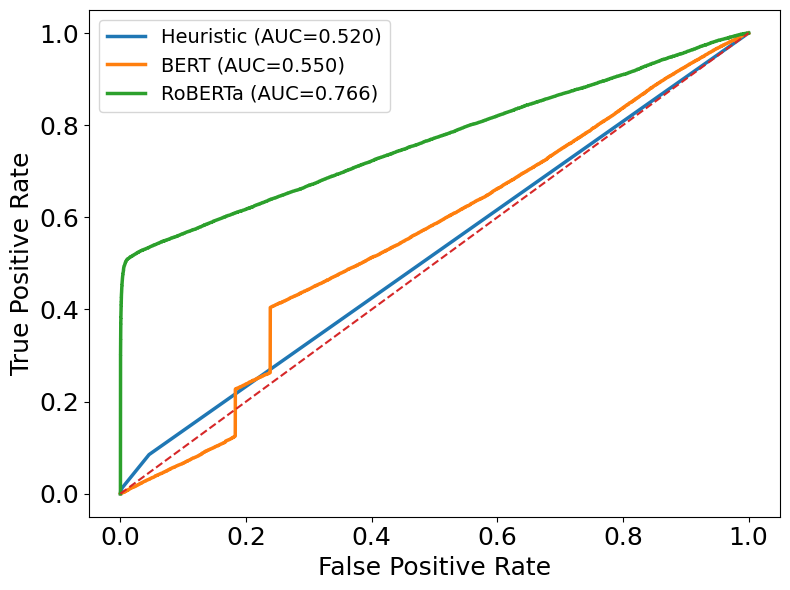

In [53]:
from sklearn.metrics import roc_curve, auc


plt.figure(figsize=(8,6))

LINE_WIDTH = 2.5
LABEL_SIZE = 18
TICK_SIZE = 18
LEGEND_SIZE = 14
TITLE_SIZE = 18

# Heuristic
fpr_h, tpr_h, _ = roc_curve(df_all['scam_likelihood'], df_all['heuristic_score'])
plt.plot(fpr_h, tpr_h, linewidth=LINE_WIDTH,
         label=f"Heuristic (AUC={auc(fpr_h, tpr_h):.3f})")

# BERT
fpr_b, tpr_b, _ = roc_curve(df_all['scam_likelihood'], df_all['bert_score'])
plt.plot(fpr_b, tpr_b, linewidth=LINE_WIDTH,
         label=f"BERT (AUC={auc(fpr_b, tpr_b):.3f})")

# RoBERTa
fpr_r, tpr_r, _ = roc_curve(df_all['scam_likelihood'], df_all['roberta_score'])
plt.plot(fpr_r, tpr_r, linewidth=LINE_WIDTH,
         label=f"RoBERTa (AUC={auc(fpr_r, tpr_r):.3f})")

# Random baseline
plt.plot([0,1], [0,1], linestyle='--', linewidth=1.5)

# Labels
plt.xlabel("False Positive Rate", fontsize=LABEL_SIZE)
plt.ylabel("True Positive Rate", fontsize=LABEL_SIZE)
# plt.title("ROC Curve Comparison", fontsize=TITLE_SIZE)

# Tick sizes
plt.xticks(fontsize=TICK_SIZE)
plt.yticks(fontsize=TICK_SIZE)

# Legend
plt.legend(fontsize=LEGEND_SIZE)

plt.tight_layout()
plt.show()


In [54]:
# from sklearn.metrics import roc_curve, auc

# plt.figure(figsize=(8,6))

# # Use scam_likelihood as the true label
# fpr_h, tpr_h, _ = roc_curve(df_all['scam_likelihood'], df_all['heuristic_score'])
# plt.plot(fpr_h, tpr_h, label=f"Heuristic (AUC={auc(fpr_h, tpr_h):.3f})")

# fpr_b, tpr_b, _ = roc_curve(df_all['scam_likelihood'], df_all['bert_score'])
# plt.plot(fpr_b, tpr_b, label=f"BERT (AUC={auc(fpr_b, tpr_b):.3f})")

# fpr_r, tpr_r, _ = roc_curve(df_all['scam_likelihood'], df_all['roberta_score'])
# plt.plot(fpr_r, tpr_r, label=f"RoBERTa (AUC={auc(fpr_r, tpr_r):.3f})")

# plt.plot([0,1], [0,1], linestyle='--')
# plt.xlabel("False Positive Rate")
# plt.ylabel("True Positive Rate")
# plt.title("ROC Curve Comparison")
# plt.legend()
# plt.tight_layout()
# plt.show()


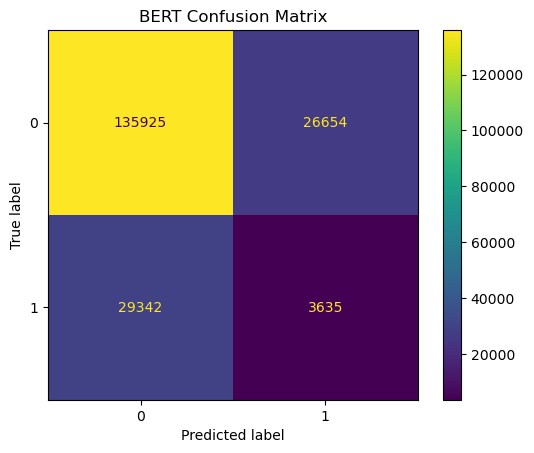

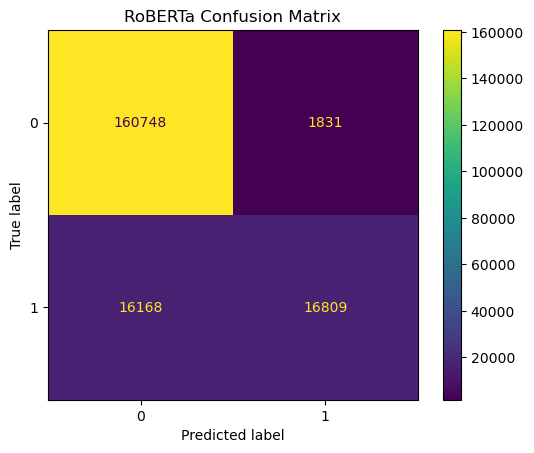

In [55]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve

true_label = df_all['scam_likelihood'].astype(int)
fpr, tpr, thresholds = roc_curve(true_label, df_all['roberta_score'])
best_threshold = thresholds[np.argmax(tpr - fpr)]


# Prepare predictions and true labels
bert_pred = (df_all['bert_score'] > 0.5).astype(int)
# roberta_pred = (df_all['roberta_score'] > 0.5).astype(int)
roberta_pred = (df_all['roberta_score'] >= best_threshold).astype(int)

# BERT
cm_bert = confusion_matrix(true_label, bert_pred)
ConfusionMatrixDisplay(cm_bert).plot()
plt.title("BERT Confusion Matrix")
plt.show()

# RoBERTa
cm_roberta = confusion_matrix(true_label, roberta_pred)
ConfusionMatrixDisplay(cm_roberta).plot()
plt.title("RoBERTa Confusion Matrix")
plt.show()


In [56]:
from sklearn.metrics import precision_score, recall_score, f1_score
def compute_metrics(y_true, y_pred):
    return {
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }
metrics_heuristic = compute_metrics(true_label, heuristic_pred)
metrics_bert = compute_metrics(true_label, bert_pred)
metrics_roberta = compute_metrics(true_label, roberta_pred)
import pandas as pd

metrics_df = pd.DataFrame.from_dict(
    {
        "Heuristic": metrics_heuristic,
        "BERT": metrics_bert,
        "RoBERTa": metrics_roberta
    },
    orient="index"
)

metrics_df
# metrics_df.round(4).to_latex()


,Precision,Recall,F1-score
Heuristic,0.490975,0.012372,0.024136
BERT,0.120011,0.110228,0.114912
RoBERTa,0.901770,0.509719,0.651297


Scam Severity trend over time(score-based) -> instead of just volume, this shows how dangeroud each scam became.

In [58]:
# # Average Roberta scam score per year per scam
# severity_trend = df_all.groupby(['year', 'source']).agg(
#     avg_roberta_score=('roberta_score', 'mean'), 
#     avg_bert_score=('bert_score', 'mean')).reset_index()

# Re-create df_24_25 to ensure 'roberta_score' exists
df_24_25 = df_all[df_all['year'].isin([2023, 2024, 2025])]

severity_24_25 = (
    df_24_25
    .groupby(['year_month', 'source'])
    .agg(avg_roberta_score=('roberta_score', 'mean'))
    .reset_index()
)

severity_24_25['year_month'] = severity_24_25['year_month'].astype(str)


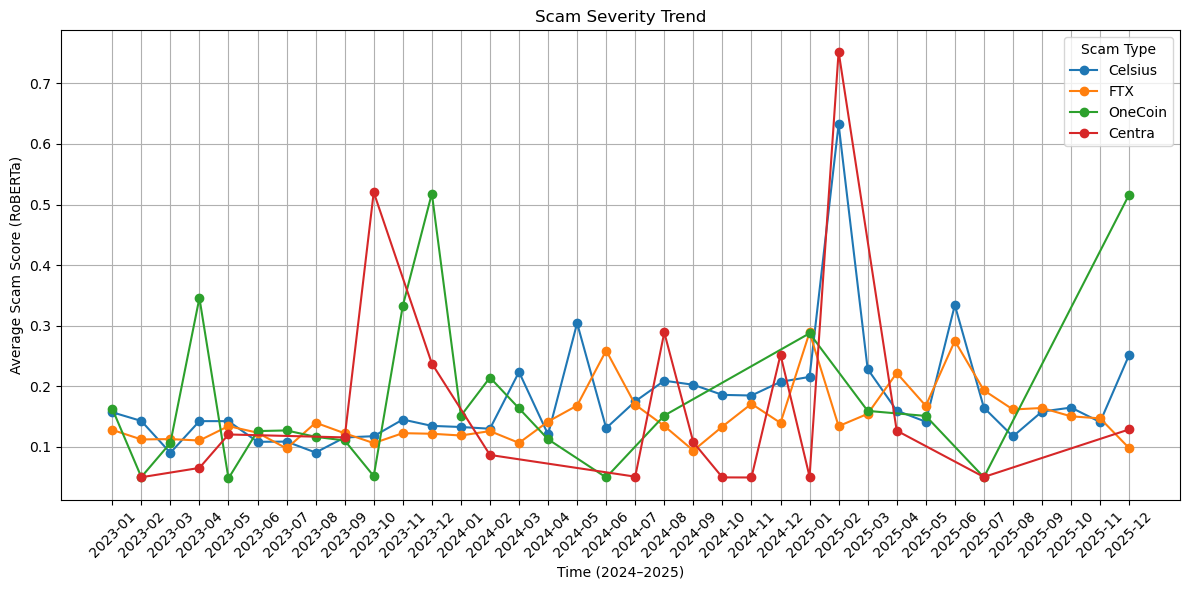

In [59]:
plt.figure(figsize=(12,6))

for scam in severity_24_25['source'].unique():
    temp = severity_24_25[severity_24_25['source'] == scam]
    plt.plot(
        temp['year_month'],
        temp['avg_roberta_score'],
        marker='o',
        label=scam
    )

plt.xlabel("Time (2024–2025)")
plt.ylabel("Average Scam Score (RoBERTa)")
plt.title("Scam Severity Trend")
plt.xticks(rotation=45)
plt.legend(title="Scam Type")
plt.grid(True)
plt.tight_layout()
plt.show()


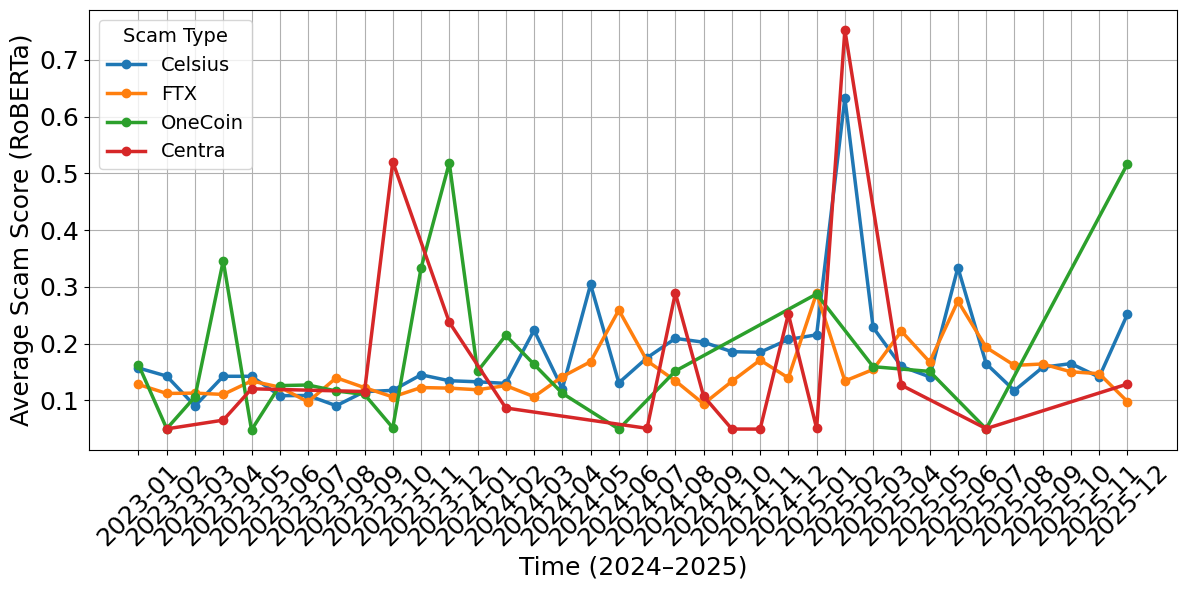

In [60]:
# plt.figure(figsize=(12,6))

# for scam in severity_24_25['source'].unique():
#     temp = severity_24_25[severity_24_25['source'] == scam]
#     plt.plot(
#         temp['year_month'],
#         temp['avg_roberta_score'],
#         marker='o',
#         label=scam
#     )

# plt.xlabel("Time (2024–2025)")
# plt.ylabel("Average Scam Score (RoBERTa)")
# plt.title("Scam Severity Trend")
# plt.xticks(rotation=45)
# plt.legend(title="Scam Type")
# plt.grid(True)
# plt.tight_layout()
# plt.show()




plt.figure(figsize=(12,6))

LINE_WIDTH = 2.5
LABEL_SIZE = 18
TICK_SIZE = 18
LEGEND_SIZE = 14
TITLE_SIZE = 18
MARKER_SIZE = 6

for scam in severity_24_25['source'].unique():
    temp = severity_24_25[severity_24_25['source'] == scam]
    plt.plot(
        temp['year_month'],
        temp['avg_roberta_score'],
        marker='o',
        linewidth=LINE_WIDTH,
        markersize=MARKER_SIZE,
        label=scam
    )

plt.xlabel("Time (2024–2025)", fontsize=LABEL_SIZE)
plt.ylabel("Average Scam Score (RoBERTa)", fontsize=LABEL_SIZE)
# plt.title("Scam Severity Trend", fontsize=TITLE_SIZE)

plt.xticks(rotation=45, fontsize=TICK_SIZE)
plt.yticks(fontsize=TICK_SIZE)

plt.legend(title="Scam Type", fontsize=LEGEND_SIZE, title_fontsize=LEGEND_SIZE)

plt.grid(True, linewidth=0.8)
plt.tight_layout()
plt.show()


Rising line → scam messages becoming more sophisticated

Flat line → consistent scam pattern

Drop → reduced activity / exposed scam

In [61]:
# norm_24_25 = count_24_25.copy()

# norm_24_25['norm_count'] = norm_24_25.groupby('source')['count'] \
#     .transform(lambda x: x / x.max())


In [62]:
# plt.figure(figsize=(12,6))

# for scam in norm_24_25['source'].unique():
#     temp = norm_24_25[norm_24_25['source'] == scam]
#     plt.plot(
#         temp['year_month'],
#         temp['norm_count'],
#         marker='o',
#         label=scam
#     )

# plt.xlabel("Time (2024–2025)")
# plt.ylabel("Normalized Scam Growth")
# plt.title("Relative Growth of Scam Types")
# plt.xticks(rotation=45)
# plt.legend(title="Scam Type")
# plt.grid(True)
# plt.tight_layout()
# plt.show()


In [63]:
# final_summary = df_all.groupby('source').agg(
#     total_msgs=('text', 'count'),
#     first_year=('year', 'min'),
#     last_year=('year', 'max'),
#     avg_roberta_score=('roberta_score', 'mean'),
#     avg_bert_score=('bert_score', 'mean')
# ).reset_index()

# final_summary


OVERALL SCAM GROWTH RATE

In [64]:
# NORMALIZE heuristic score to [0,1] range
df_all["heuristic_prob"] = (
    df_all["heuristic_score"] / df_all["heuristic_score"].max()
)


MONTHLY SCAM GROWTH RATE

In [65]:
monthly_trend = (
    df_all
    .groupby("year_month")[["heuristic_prob", "bert_score", "roberta_score"]]
    .mean()
    .reset_index()
    .sort_values("year_month")
)


In [66]:
monthly_growth = monthly_trend.copy()

monthly_growth[["heuristic_growth_%", "bert_growth_%", "roberta_growth_%"]] = (
    monthly_trend[["heuristic_prob", "bert_score", "roberta_score"]]
    .pct_change() * 100
)


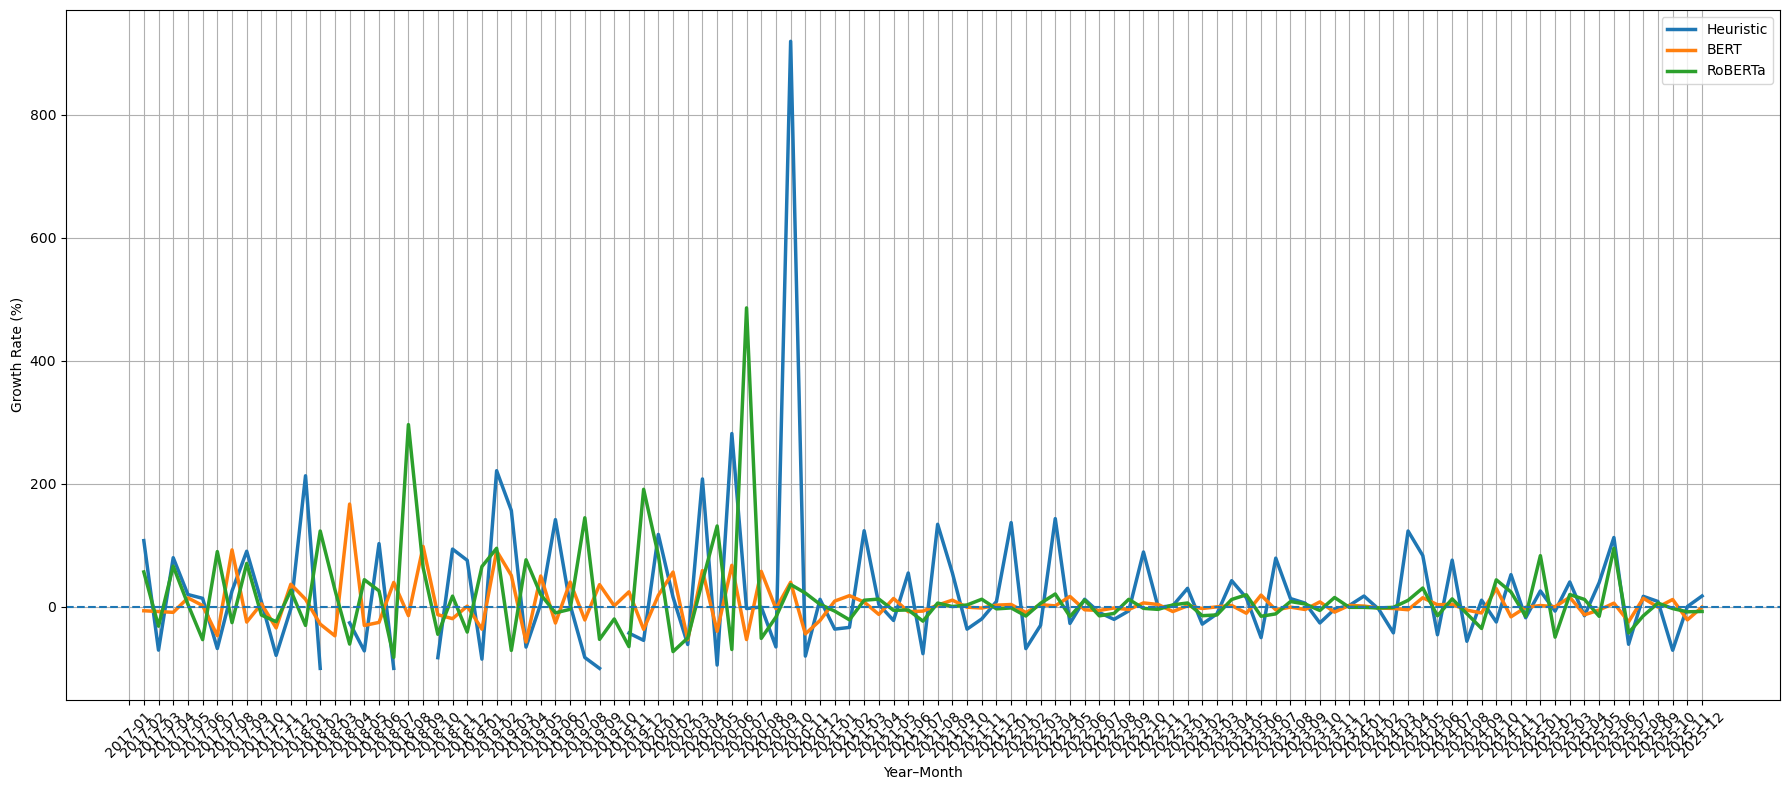

In [68]:
# plt.figure(figsize=(12, 5))

# plt.plot(monthly_growth["year_month"].astype(str), monthly_growth["heuristic_growth_%"], label="Heuristic")
# plt.plot(monthly_growth["year_month"].astype(str), monthly_growth["bert_growth_%"], label="BERT")
# plt.plot(monthly_growth["year_month"].astype(str), monthly_growth["roberta_growth_%"], label="RoBERTa")

# plt.axhline(0, linestyle="--")
# plt.xticks(rotation=45)
# plt.xlabel("Year–Month")
# plt.ylabel("Growth Rate (%)")
# plt.title("Monthly Overall Scam Growth Rate")
# plt.legend()
# plt.grid(True)
# plt.show()


plt.figure(figsize=(18, 8))

LINE_WIDTH = 2.5
LABEL_SIZE = 10
TICK_SIZE = 10
LEGEND_SIZE = 10
TITLE_SIZE = 12

plt.plot(
    monthly_growth["year_month"].astype(str),
    monthly_growth["heuristic_growth_%"],
    linewidth=LINE_WIDTH,
    label="Heuristic"
)

plt.plot(
    monthly_growth["year_month"].astype(str),
    monthly_growth["bert_growth_%"],
    linewidth=LINE_WIDTH,
    label="BERT"
)

plt.plot(
    monthly_growth["year_month"].astype(str),
    monthly_growth["roberta_growth_%"],
    linewidth=LINE_WIDTH,
    label="RoBERTa"
)

plt.axhline(0, linestyle="--", linewidth=1.5)

plt.xticks(rotation=45, fontsize=TICK_SIZE)
plt.yticks(fontsize=TICK_SIZE)

plt.xlabel("Year–Month", fontsize=LABEL_SIZE)
plt.ylabel("Growth Rate (%)", fontsize=LABEL_SIZE)
# plt.title("Monthly Overall Scam Growth Rate", fontsize=TITLE_SIZE)

plt.legend(fontsize=LEGEND_SIZE)
plt.grid(True, linewidth=0.8)

plt.tight_layout()
plt.show()


In [69]:
monthly_growth.head()


,year_month,heuristic_prob,bert_score,roberta_score,heuristic_growth_%,bert_growth_%,roberta_growth_%
0,2017-01,0.020000,0.448757,0.106696,NaN,NaN,NaN
1,2017-02,0.041548,0.420525,0.167309,107.740467,-6.291288,56.809319
2,2017-03,0.012315,0.388661,0.114777,-70.358999,-7.577095,-31.398327
3,2017-04,0.022161,0.354113,0.190742,79.944598,-8.888942,66.185448
4,2017-05,0.026611,0.405790,0.198749,20.080532,14.593216,4.197776


CAGR (Compound Annual Growth Rate)

In [71]:
# Aggregate yearly RoBERTa score
yearly_trend = (
    df_all
    .groupby("year")["roberta_score"]
    .mean()
    .sort_index()
)

start_value = yearly_trend.iloc[0]
end_value   = yearly_trend.iloc[-1]
num_years   = yearly_trend.index[-1] - yearly_trend.index[0]

cagr = (end_value / start_value) ** (1 / num_years) - 1

print(f"Overall Scam CAGR (RoBERTa): {cagr * 100:.2f}%")
# CAGR > 0 → long-term increase in scam activity

# CAGR < 0 → declining trend


Overall Scam CAGR (RoBERTa): -0.70%


In [72]:
pd.DataFrame({
    "Start Year": [yearly_trend.index[0]],
    "End Year": [yearly_trend.index[-1]],
    "CAGR (%)": [cagr * 100]
})


,Start Year,End Year,CAGR (%)
0,2017,2025,-0.699568


Per-Scam Growth (FTX vs OneCoin vs Centra)

In [73]:
scam_monthly = (
    df_all
    .groupby(["year_month", "source"])["roberta_score"]
    .mean()
    .reset_index()
    .sort_values(["source", "year_month"])
)


In [74]:
scam_monthly["growth_rate_%"] = (
    scam_monthly
    .groupby("source")["roberta_score"]
    .pct_change() * 100
)


FTX → sharp spike around collapse year

OneCoin → early surge, later stagnation

Centra → short-lived growth

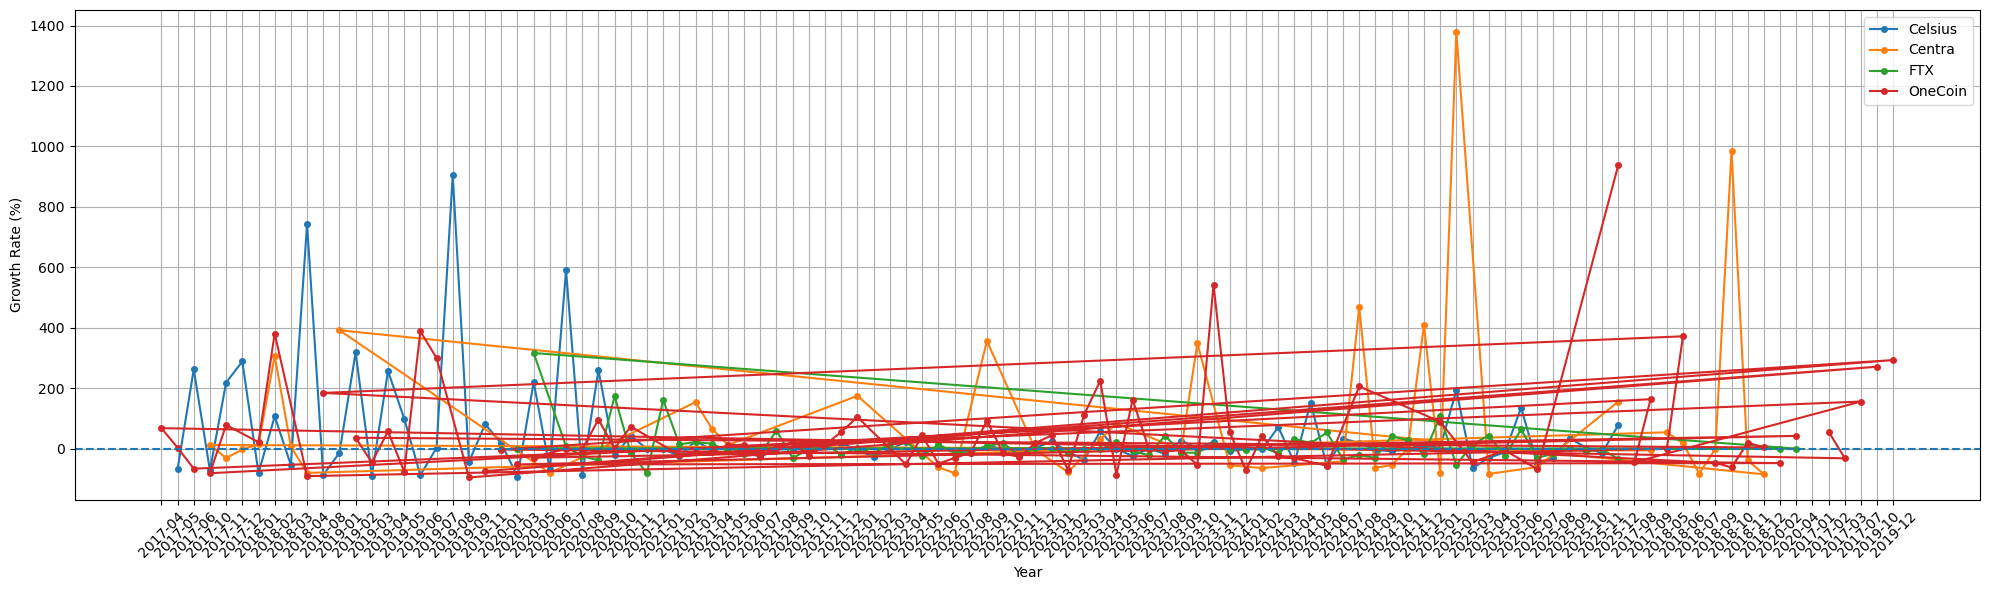

In [76]:
# import matplotlib.pyplot as plt

# plt.figure(figsize=(10, 5))

# for scam in scam_monthly["source"].unique():
#     subset = scam_monthly[scam_monthly["source"] == scam]
#     plt.plot(
#         subset["year_month"],
#         subset["growth_rate_%"],
#         marker="o",
#         label=scam
#     )

# plt.axhline(0, linestyle="--")
# plt.xlabel("Year")
# plt.ylabel("Growth Rate (%)")
# plt.title("Per-Scam Yearly Growth Rate (RoBERTa)")
# plt.legend()
# plt.grid(True)
# plt.show()


plt.figure(figsize=(20, 6))

LINE_WIDTH = 1.5
LABEL_SIZE = 10
TICK_SIZE = 10
LEGEND_SIZE = 10
TITLE_SIZE = 10
MARKER_SIZE = 4

for scam in scam_monthly["source"].unique():
    subset = scam_monthly[scam_monthly["source"] == scam]
    plt.plot(
        subset["year_month"],
        subset["growth_rate_%"],
        marker="o",
        linewidth=LINE_WIDTH,
        markersize=MARKER_SIZE,
        label=scam
    )

plt.axhline(0, linestyle="--", linewidth=1.5)

plt.xticks(rotation = 45, fontsize=TICK_SIZE)
plt.yticks(fontsize=TICK_SIZE)

plt.xlabel("Year", fontsize=LABEL_SIZE)
plt.ylabel("Growth Rate (%)", fontsize=LABEL_SIZE)
# plt.title("Per-Scam Yearly Growth Rate (RoBERTa)", fontsize=TITLE_SIZE)

plt.legend(fontsize=LEGEND_SIZE)
plt.grid(True, linewidth=0.8)

plt.tight_layout()
plt.show()


In [77]:
df_all['year_month'] = pd.to_datetime(df_all['year_month'], format='%Y-%m')

df_all['year_month'].dtype


dtype('<M8[ns]')

In [78]:
cagr_per_scam = []

for scam in df_all["source"].unique():
    temp = (
        df_all[df_all["source"] == scam]
        .groupby("year_month")["roberta_score"]
        .mean()
        .sort_index()
    )

    if len(temp) > 1:
        start = temp.iloc[0]
        end = temp.iloc[-1]

        # Total number of months between first and last entry
        months = (temp.index[-1].year - temp.index[0].year) * 12 + \
                 (temp.index[-1].month - temp.index[0].month)

        if months > 0 and start > 0:
            scam_cagr = (end / start) ** (1 / months) - 1
            cagr_per_scam.append([scam, scam_cagr * 100])

cagr_df = pd.DataFrame(cagr_per_scam, columns=["Scam", "CAGR (%)"])
cagr_df


,Scam,CAGR (%)
0,OneCoin,1.484787
1,FTX,0.935256
2,Centra,-0.433964
3,Celsius,0.502419


In [ ]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [79]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    class_weight='balanced',   # handles your scam/non-scam imbalance
    random_state=42
)
lgbm.fit(X_train, Y_train)
lgbm_probs = lgbm.predict_proba(X_test)[:, 1]
print(classification_report(Y_test, lgbm.predict(X_test)))
print("ROC-AUC:", roc_auc_score(Y_test, lgbm_probs))

[LightGBM] [Info] Number of positive: 23159, number of negative: 113730
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002963 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 810
[LightGBM] [Info] Number of data points in the train set: 136889, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
              precision    recall  f1-score   support

       False       0.91      0.99      0.95     48849
        True       0.94      0.51      0.66      9818

    accuracy                           0.91     58667
   macro avg       0.93      0.75      0.81     58667
weighted avg       0.92      0.91      0.90     58667

ROC-AUC: 0.7717063224434425


In [ ]:
%pip install catboost

In [80]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    auto_class_weights='Balanced',
    verbose=0,
    random_seed=42
)
cat.fit(X_train, Y_train)
cat_probs = cat.predict_proba(X_test)[:, 1]
print(classification_report(Y_test, cat.predict(X_test)))

              precision    recall  f1-score   support

       False       0.91      0.99      0.95     48849
        True       0.94      0.51      0.66      9818

    accuracy                           0.91     58667
   macro avg       0.93      0.75      0.81     58667
weighted avg       0.92      0.91      0.90     58667



In [81]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

base_models = [
    ('rf',   RandomForestClassifier(n_estimators=200, random_state=42)),
    ('xgb',  XGBClassifier(n_estimators=300, random_state=42, eval_metric='logloss')),
    ('lgbm', LGBMClassifier(n_estimators=500, random_state=42)),
    ('cat',  CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, auto_class_weights='Balanced', verbose=0, random_seed=42))
    # ('svm',  SVC(kernel='linear', probability=True, class_weight='balanced'))
]

# Logistic Regression learns how to best combine them
stack = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(),
    cv=5,
    passthrough=True   # also passes original features to meta-learner
)
stack.fit(X_train, Y_train)
stack_probs = stack.predict_proba(X_test)[:, 1]
print("Stack AUC:", roc_auc_score(Y_test, stack_probs))

[LightGBM] [Info] Number of positive: 23159, number of negative: 113730
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002092 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 810
[LightGBM] [Info] Number of data points in the train set: 136889, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.169181 -> initscore=-1.591444
[LightGBM] [Info] Start training from score -1.591444
[LightGBM] [Info] Number of positive: 18527, number of negative: 90984
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002289 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 807
[LightGBM] [Info] Number of data points in the train set: 109511, number of used features: 6
[LightGBM] [Info] [

c:\Users\User\anaconda3\lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  )


Stack AUC: 0.775276616124452


In [83]:
# import shap

# explainer    = shap.TreeExplainer(xgb_model)
# shap_values  = explainer.shap_values(X_test)

# # Summary — which features matter most overall
# shap.summary_plot(shap_values, X_test)

# # For a single post — why was this one flagged?
# shap.waterfall_plot(shap.Explanation(
#     values     = shap_values[0],
#     base_values= explainer.expected_value,
#     data       = X_test.iloc[0],
#     feature_names=FEATURES
# ))

NLP/Text-specific algorithms

BERTopic - discovers what scam narratives actually exit in your data

In [ ]:
%pip install bertopic


  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
    Preparing wheel metadata: started
    Preparing wheel metadata: finished with status 'done'
  Using cached scikit_learn-1.6.1-cp39-cp39-win_amd64.whl (11.2 MB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)
  Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
  Using cached transformers-4.57.6-py3-none-any.whl (12.0 MB)
  Using cached safetensors-0.7.0-cp38-abi3-win_amd64.whl (341 kB)
  Created wheel for hdbscan: filename=hdbscan-0.8.42-cp39-cp39-win_amd64.whl size=675882 sha256=669b066b7668253157f2c1b75b1369d62afcd2c2c7cbcea0da765f56ba057735
  Stored in directory: c:\users\user\appdata\local\pip\cache\wheels\ed\0d\10\77e52180d41859778f847c91db4c9d7c19af9d3b9975268d1c
Successfully built hdbscan
  Attempting uninstall: threadpoolctl
    Found existing inst

In [84]:
import sys
import subprocess
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--upgrade", "scipy", "scikit-learn",
    "--user"          # installs to user folder, bypasses Anaconda lock
])

0

In [ ]:
# Force reinstall hdbscan without touching llvmlite
%pip install hdbscan --no-cache-dir --no-deps
%pip install scipy --upgrade
%pip install scikit-learn --upgrade

Note: you may need to restart the kernel to use updated packages.




In [ ]:
# Install bertopic + only the dependencies it actually needs
%pip install bertopic
%pip install umap-learn
%pip install sentence-transformers

ERROR: Cannot uninstall 'llvmlite'. It is a distutils installed project and thus we cannot accurately determine which files belong to it which would lead to only a partial uninstall.



  Using cached numba-0.60.0-cp39-cp39-win_amd64.whl (2.7 MB)
  Using cached llvmlite-0.43.0-cp39-cp39-win_amd64.whl (28.1 MB)
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.38.0
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
daal4py 2021.5.0 requires daal==2021.4.0, which is not installed.
torchvision 0.13.1 requires torch==1.12.1, but you have torch 2.8.0 which is incompatible.


  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: scipy
    Found existing installation: scipy 1.13.1
    Uninstalling scipy-1.13.1:
      Successfully uninstalled scipy-1.13.1



In [85]:
from bertopic import BERTopic
import pandas as pd

df_all['timestamp_utc'] = pd.to_datetime(df_all['timestamp_utc'], errors='coerce')
df_all = df_all.dropna(subset=['cleaned_text', 'timestamp_utc'])

texts      = df_all['cleaned_text'].tolist()
timestamps = df_all['timestamp_utc'].tolist()

topic_model = BERTopic(
    language               = "english",
    calculate_probabilities = True,
    nr_topics              = 15,
    min_topic_size         = 10,
    verbose                = True
)

topics, probs        = topic_model.fit_transform(texts)
df_all['topic']      = topics
df_all['topic_prob'] = [max(p) for p in probs]

print(topic_model.get_topic_info())
topic_model.visualize_topics()
topic_model.visualize_barchart(top_n_topics=10)

topics_over_time = topic_model.topics_over_time(
    docs       = texts,
    timestamps = timestamps,
    nr_bins    = 20
)
topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10)

ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject

Named Entity Recognition (NER) - extract wallet addresses, exchange names, scam URLs automatically

In [ ]:
# pip install spacy && python -m spacy download en_core_web_sm
import spacy
nlp = spacy.load("en_core_web_sm")

def extract_entities(text):
    doc = nlp(str(text)[:512])
    return {
        'orgs':     [e.text for e in doc.ents if e.label_ == 'ORG'],
        'persons':  [e.text for e in doc.ents if e.label_ == 'PERSON'],
        'money':    [e.text for e in doc.ents if e.label_ == 'MONEY'],
        'urls':     [e.text for e in doc.ents if e.label_ == 'URL']
    }

df_all['entities'] = df_all['text'].apply(extract_entities)
df_all['mentioned_orgs'] = df_all['entities'].apply(lambda x: x['orgs'])

# Which organisations are most mentioned in scam posts?
scam_posts = df_all[df_all['scam_likelihood'] == 1]
from collections import Counter
org_counts = Counter(
    org for orgs in scam_posts['mentioned_orgs'] for org in orgs
)
print(org_counts.most_common(20))

Change point detection - formally detect when a scam narrative structurally shifted

In [86]:
%pip install ruptures

OneCoin: Change points at time indices [85]


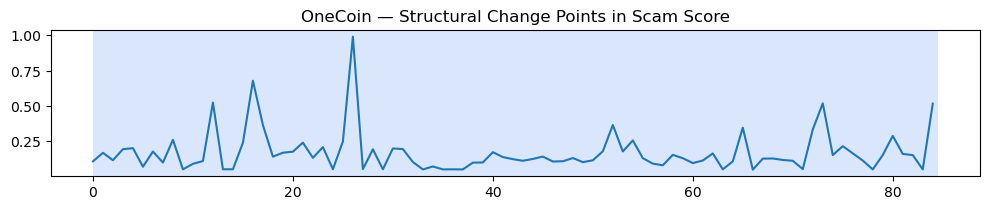

FTX: Change points at time indices [5, 20, 35, 50, 72]


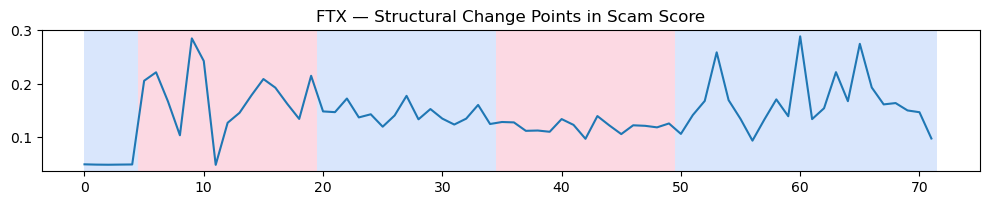

Centra: Change points at time indices [44]


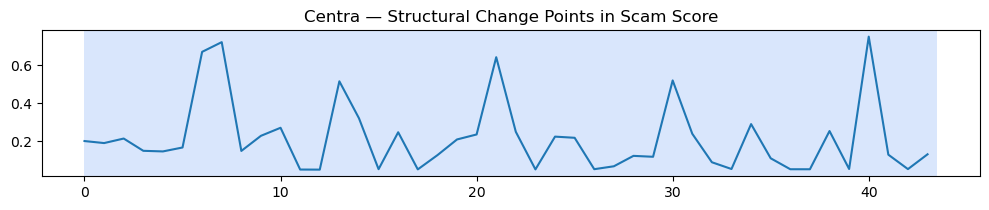

Celsius: Change points at time indices [30, 45, 70, 91]


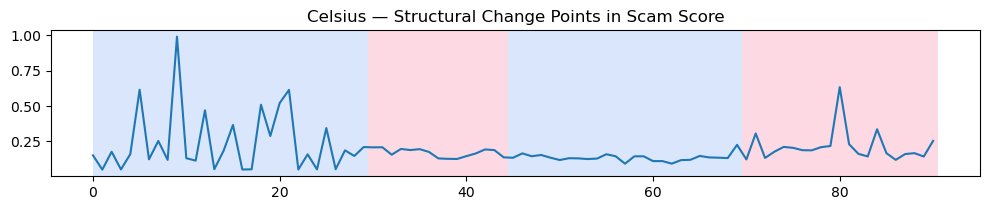

In [87]:
# pip install ruptures
import ruptures as rpt

for scam in df_all['source'].unique():
    signal = (
        df_all[df_all['source'] == scam]
        .groupby('year_month')['roberta_score']
        .mean()
        .values
    )
    if len(signal) < 4:
        continue

    algo   = rpt.Pelt(model="rbf").fit(signal)
    result = algo.predict(pen=2)
    print(f"{scam}: Change points at time indices {result}")

    # Plot
    rpt.display(signal, result)
    plt.title(f"{scam} — Structural Change Points in Scam Score")
    plt.show()

Time series forecasting with prophet - predict future scam activity

In [88]:
%pip install prophet

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ------------ --------------------------- 3.9/12.1 MB 23.5 MB/s eta 0:00:01
   ---------------------------------------- 12.1/12.1 MB 33.0 MB/s  0:00:00
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 13.4 MB/s  0:00:00

   ---------------------------------------- 0/4 [stanio]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 

16:16:01 - cmdstanpy - INFO - Chain [1] start processing
16:16:01 - cmdstanpy - INFO - Chain [1] done processing


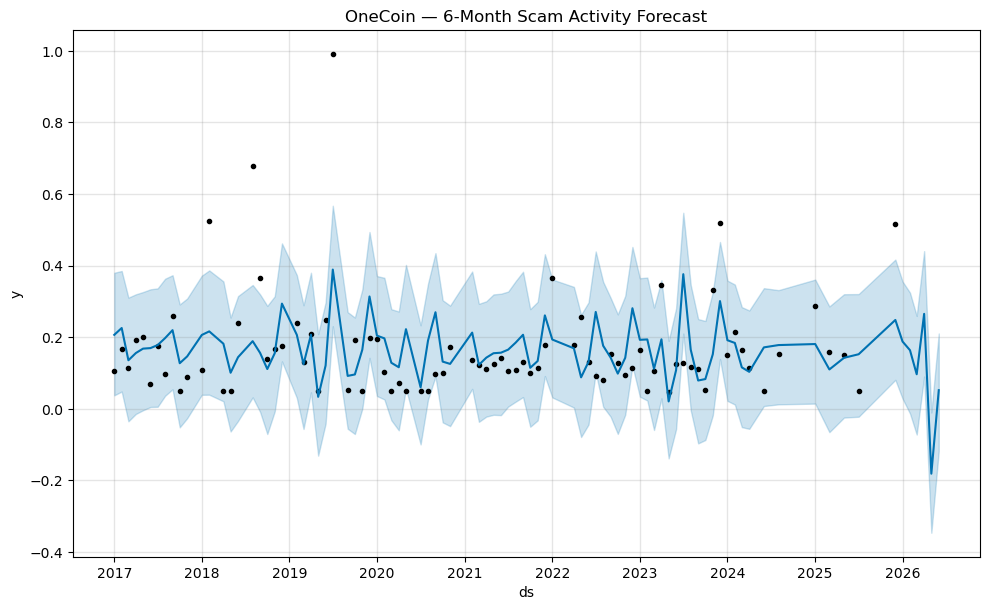

16:16:02 - cmdstanpy - INFO - Chain [1] start processing
16:16:02 - cmdstanpy - INFO - Chain [1] done processing


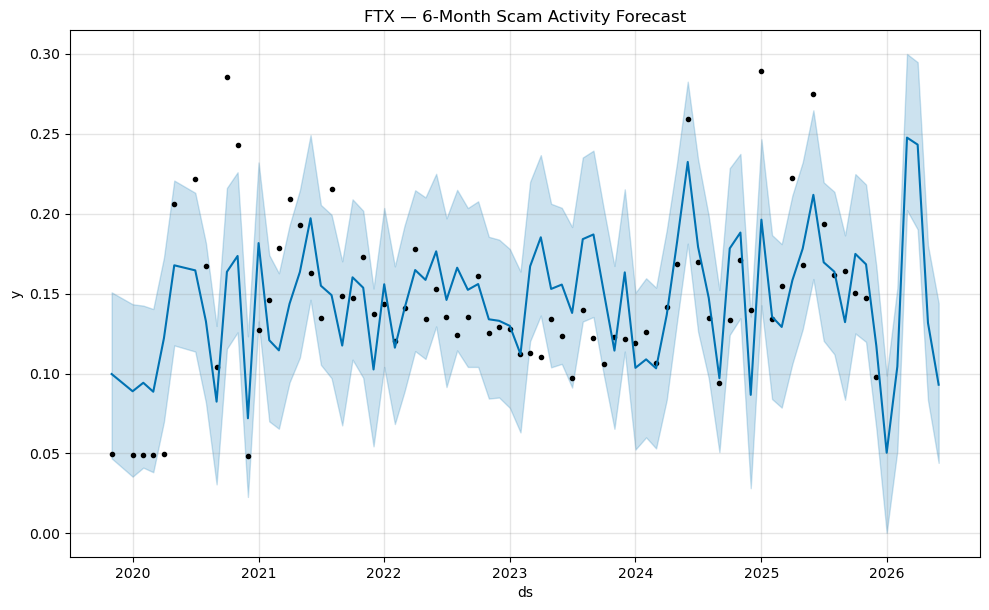

16:16:03 - cmdstanpy - INFO - Chain [1] start processing
16:16:03 - cmdstanpy - INFO - Chain [1] done processing


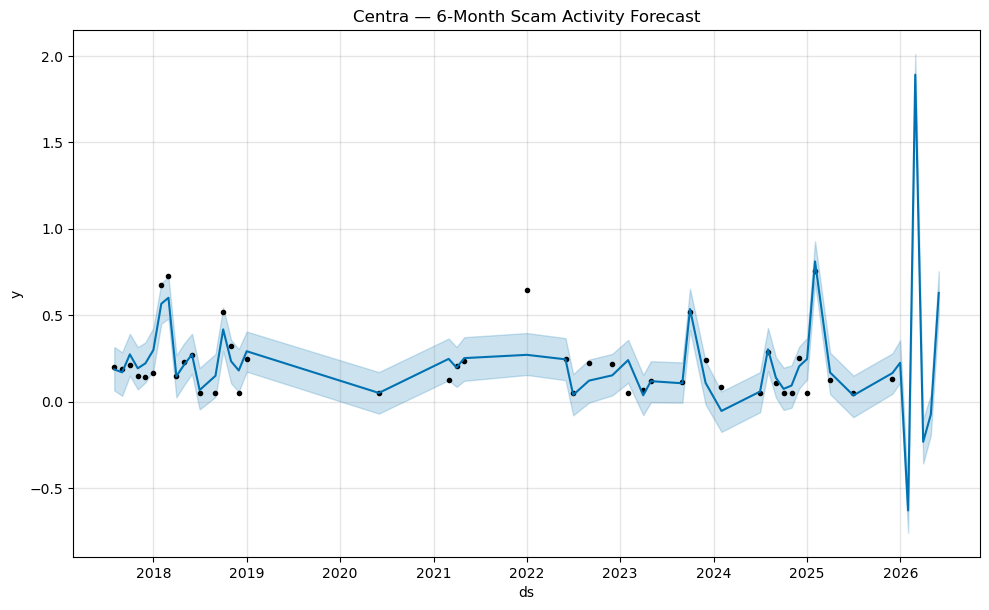

16:16:03 - cmdstanpy - INFO - Chain [1] start processing
16:16:04 - cmdstanpy - INFO - Chain [1] done processing


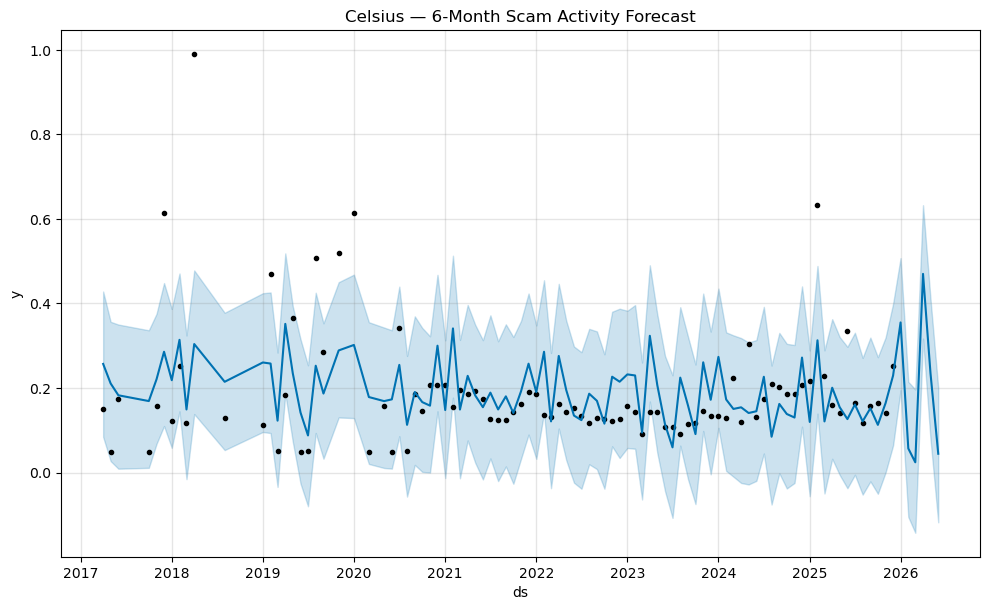

In [89]:
# pip install prophet
from prophet import Prophet

for scam in df_all['source'].unique():
    ts = (
        df_all[df_all['source'] == scam]
        .groupby('year_month')['roberta_score']
        .mean()
        .reset_index()
    )
    ts.columns = ['ds', 'y']
    ts['ds']   = pd.to_datetime(ts['ds'].astype(str))

    m = Prophet(yearly_seasonality=True, weekly_seasonality=False)
    m.fit(ts)

    future   = m.make_future_dataframe(periods=6, freq='M')
    forecast = m.predict(future)

    m.plot(forecast)
    plt.title(f"{scam} — 6-Month Scam Activity Forecast")
    plt.show()

Quick way to compare all pre-trained model together

In [90]:
from transformers import pipeline

models_to_compare = {
    "BERTweet":    "vinai/bertweet-base",
    "CryptoBERT":  "kk08/CryptoBERT",
    "DeBERTa":     "microsoft/deberta-v3-base",
}

results = {}
sample_texts = df_all['text'].head(500).tolist()  # test on 500 posts first

for name, model_path in models_to_compare.items():
    print(f"Running {name}...")
    clf = pipeline("zero-shot-classification",
                   model=model_path, device=-1)
    scores = []
    for text in sample_texts:
        res = clf(str(text)[:512],
                  ["cryptocurrency scam", "legitimate discussion"])
        scores.append(res['scores'][res['labels'].index("cryptocurrency scam")])
    results[name] = scores
    print(f"{name} done. Mean score: {sum(scores)/len(scores):.3f}")

# Add to dataframe for comparison
for name, scores in results.items():
    df_all.loc[df_all.index[:500], f'{name}_score'] = scores

Running BERTweet...


config.json:   0%|          | 0.00/558 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


pytorch_model.bin:   0%|          | 0.00/543M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at vinai/bertweet-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Failed to determine 'entailment' label id from the label2id mapping in the model config. Setting to -1. Define a descriptive label2id mapping in the model config to ensure correct outputs.
Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "c:\Users\User\anaconda3\lib\site-packages\IPython\core\interactiveshell.py", line 3526, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "C:\Users\User\AppData\Local\Temp\ipykernel_17904\1586795592.py", line 18, in <module>
    res = clf(str(text)[:512],
  File "c:\Users\User\anaconda3\lib\site-packages\transformers\pipelines\zero_shot_classification.py", line 206, in __call__
    return super().__call__(sequences, **kwargs)
  File "c:\Users\User\anaconda3\lib\site-packages\transformers\pipelines\base.py", line 1260, in __call__
  File "c:\Users\User\anaconda3\lib\site-packages\transformers\pipelines\pt_utils.py", line 124, in __next__
    item = next(self.iterator)
  File "c:\Users\User\anaconda3\lib\site-packages\transformers\pipelines\pt_utils.py", line 269, in __next__
    first_tensor = processed
  File "c:\Users\User\anaconda3\lib\site-packages\transformers\pipelines\base.py", line 1175, in forward
    "For ChunkP

More accurate analysis techniques

Cross-validation (most important fix)

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in [('XGB', xgb_model), ('RF', classify), ('LGBM', lgbm)]:
    scores = cross_validate(
        model, target, labels, cv=cv,
        scoring=['roc_auc', 'f1', 'precision', 'recall']
    )
    print(f"\n{name}:")
    for metric, vals in scores.items():
        if metric.startswith('test_'):
            print(f"  {metric[5:]}: {vals.mean():.3f} ± {vals.std():.3f}")

Calibration curves - check if probabilities are reliable

In [ ]:
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

plt.figure(figsize=(8, 6))

for name, probs in [('XGB', xgb_probs), ('RF', rf_probs),
                     ('RoBERTa', df_all.loc[X_test.index, 'roberta_score'])]:
    fraction_pos, mean_pred = calibration_curve(Y_test, probs, n_bins=10)
    plt.plot(mean_pred, fraction_pos, marker='o', label=name)

plt.plot([0,1], [0,1], linestyle='--', label='Perfectly calibrated')
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curves — Are Probabilities Trustworthy?")
plt.legend()
plt.show()

Precision-recall curve - more informative than ROC for imbalanced data

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for name, probs in [
    ('Heuristic', df_all['heuristic_prob']),
    ('XGBoost',   xgb_probs),
    ('RoBERTa',   df_all.loc[X_test.index, 'roberta_score'])
]:
    p, r, _ = precision_recall_curve(Y_test, probs)
    ap      = average_precision_score(Y_test, probs)
    plt.plot(r, p, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.show()

For Multiclass classification:

code change for multiclas in your existing RoBERTa setup:

# Change num_labels
model = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=4  # was 2
)

# Change label mapping
df_all['label'] = df_all['source'].map(
    {'OneCoin': 0, 'CentraTech': 1, 'Celsius': 2, 'FTX': 3}
)

# Change metrics to macro-averaged
precision, recall, f1, _ = precision_recall_fscore_support(
    labels, preds, average="macro"  # not "binary"
)